## Pré-Processamento de Dados

O pré-processamento (**engenharia de dados**) é uma etapa fundamental e, frequentemente, a que consome a maior fração do tempo de um projeto de Ciência de Dados. Envolve a aquisição, limpeza, estruturação e transformação dos dados brutos em um formato digerível pelos algoritmos.

Uma vez que os dados estão tabulados, damos início à **Análise Exploratória de Dados (AED)**. A AED funciona como um diagnóstico: ela fornece a inteligência necessária para decidir quais técnicas de pré-processamento devem ser aplicadas nas etapas seguintes.

Abaixo, os pilares do pré-processamento que abordaremos:

1.  **Limpeza e Qualidade dos Dados:**
    Foco na integridade e consistência. Envolve corrigir erros de digitação, unificar formatos (ex: datas), garantir pureza e tratar **Outliers** (Univariados e Multivariados) que podem distorcer a realidade.
    * [Material de Apoio: identirficação de outliers](https://colab.research.google.com/drive/1NNldGw8P3axwKyw63WIl958LJnVmUlDP)

2.  **Tratamento de Dados Ausentes (Missing Values):**
    Decidir entre remover as observações ou aplicar técnicas de imputação (Média, Mediana, Moda ou algoritmos preditivos) para preencher as lacunas sem introduzir viés.
    * [Material de Apoio: Dados Ausentes](https://colab.research.google.com/drive/1i3BPjEwBUQX4pYTHYNrJAq8OuSe7Kho0)

3.  **Transformação de Variáveis:**
    Adaptação matemática das características para atender aos pressupostos dos modelos.
    * **Discretização (Binning):** Converter dados numéricos contínuos em faixas categóricas (ex: Idade para Faixa Etária). Útil para capturar relações não-lineares e reduzir ruído.
    * **Codificação (Encoding):** Modelos matemáticos exigem números. Variáveis categóricas (texto) devem ser convertidas via *Label Encoding* (para ordinais) ou *One-Hot Encoding* (para nominais).
    * **Correção de Assimetria (Skewness):** Aplicação de logaritmo ou outras transformações (Box-Cox) para aproximar a distribuição dos dados de uma Curva Normal (Gaussiana), facilitando o trabalho de modelos lineares e paramétricos.

4.  **Padronização e Escalonamento (Feature Scaling):**
    Crucial para algoritmos baseados em distância (KNN, SVM) e otimização por gradiente (Redes Neurais).
    * O objetivo é garantir que variáveis com magnitudes grandes (ex: Salário) não dominem variáveis com magnitudes pequenas (ex: Idade).

5.  **Seleção de Características (Feature Selection):**
    * **Remoção de Multicolinearidade:** Variáveis preditoras altamente correlacionadas entre si trazem redundância e instabilidade para modelos lineares.
    * **Remoção de Variância Quase Nula:** Variáveis que possuem o mesmo valor para quase todas as amostras não agregam poder preditivo e devem ser descartadas.

6.  **Redução de Dimensionalidade:**
    Quando o número de variáveis é alto demais, sofremos com a "Maldição da Dimensionalidade". Técnicas como PCA (Análise de Componentes Principais) comprimem a informação, mantendo o sinal e reduzindo o ruído ("Menos é Mais").

7.  **Engenharia de Recursos (Feature Engineering):**
    A arte de criar novas variáveis a partir das existentes. Combinar conhecimento de negócio com os dados (ex: criar `Valor_por_m2` dividindo `Preço` por `Area`) pode aumentar drasticamente a performance do modelo.



# Dataset Ames House Price:

Neste exercício, focaremos em um subconjunto de 12 variáveis do famoso dataset Ames para prever o preço de venda (*SalePrice*). Abaixo, detalhamos o significado e a natureza de cada uma.

## 1. Variáveis Numéricas (Quantitativas)

* **`LotArea`**: Tamanho do lote em pés quadrados.
    * *Atenção:* Valores altos (milhares). Requer escalonamento forte ou Log.
* **`YearBuilt`**: Ano original de construção.
    * *Atenção:* Embora seja numérico, representa tempo.
* **`GrLivArea`**: Área habitável acima do solo (pés quadrados).
    * *Importante:* Frequentemente a variável com maior correlação com o preço. Sujeita a outliers.
* **`GarageCars`**: Tamanho da garagem em capacidade de carros (0, 1, 2...).
    * *Atenção:* Variável discreta pequena.
* **`GarageArea`**: Tamanho da garagem em pés quadrados.
    * *Nota:* Altamente correlacionada com `GarageCars` (Risco de Multicolinearidade).

## 2. Variáveis Categóricas Ordinais
*Estas variáveis possuem uma ordem intrínseca (Ruim -> Bom). Podem ser tratadas como números (Label Encoding) respeitando a hierarquia.*

* **`OverallQual`**: Avaliação geral do material e acabamento da casa.
    * *Escala:* 1 (Muito Ruim) a 10 (Muito Excelente).
* **`FireplaceQu`**: Qualidade da lareira.
    * *Escala:* Ex (Excelente), Gd (Bom), TA (Médio), Fa (Razoável), Po (Ruim).
    * *Pegadinha:* `NaN` aqui não é dado faltante, significa **"Sem Lareira"**. Deve ser preenchido com uma categoria "Nenhuma".

## 3. Variáveis Categóricas Nominais
*Estas variáveis não possuem ordem matemática. Exigem One-Hot Encoding ou Target Encoding.*

* **`MSZoning`**: Classificação de zoneamento geral (ex: Residencial Baixa Densidade, Comercial, etc).
* **`Neighborhood`**: Bairro dentro dos limites da cidade de Ames.
    * *Desafio:* Alta cardinalidade (muitas categorias). One-Hot Encoding pode gerar colunas demais.
* **`BldgType`**: Tipo de habitação (ex: 1 família, Duplex, Townhouse).
* **`GarageType`**: Localização da garagem (ex: Anexada, Destacada, Porão).
    * *Pegadinha:* `NaN` significa **"Sem Garagem"**.
* **`Street`**: Tipo de acesso rodoviário à propriedade.
    * *Categorias:* Grvl (Cascalho) ou Pave (Pavimentado).
    * *Atenção:* Geralmente tem variância muito baixa (quase todas são pavimentadas), podendo ser descartada por "quase-constância".

## 4. Variável Alvo (Target)
*Esta é a variável dependente (Y) que o modelo tentará prever.*

* **`SalePrice`**: O preço de venda da propriedade em dólares.
    * **Tipo:** Numérico Contínuo.
    * **Distribuição:** Assimétrica à direita (*Positive Skewness*).
        * Isso significa que a maioria das casas tem preços médios, mas existe uma "cauda longa" de casas extremamente caras.
    * **Pré-processamento Recomendado:**
        * **Para Regressão Linear/KNN:** É altamente recomendável aplicar uma **Transformação Logarítmica (`np.log1p`)**. Isso "achata" a curva, aproximando os dados de uma Distribuição Normal, o que melhora muito a performance desses modelos.
        * **Para Árvores:** Não é estritamente necessário transformar, pois elas lidam bem com assimetria.

---


In [ ]:
# Importação das bibliotecas essenciais
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações de visualização para os gráficos
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')
# Aumentar o tamanho padrão das figuras
plt.rcParams['figure.figsize'] = (10, 6)
# Evitar avisos futuros de bibliotecas
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# Carregar o dataset do OpenML (datasets)
from sklearn.datasets import fetch_openml
house_prices = fetch_openml(name="house_prices", as_frame=True) # dataset
df_original = house_prices.frame

# Selecionar um subconjunto de features para a aula
features_selecionadas = [
    'LotArea', 'OverallQual', 'YearBuilt', 'GrLivArea', 'GarageCars', 'GarageArea',
    'MSZoning', 'Neighborhood', 'BldgType', 'GarageType', 'FireplaceQu', 'Street'
]
target = 'SalePrice' # varaivel alvo
df = df_original[features_selecionadas + [target]].copy() # quando copiamos apenas uma lista, x=y, caso alterarmos y,  x vera essa alteração, por isso copy(), criando assim uma nova variavel.

#  Imputação
# A maioria das funções de transformação não lida com NaNs.
# Faremos uma imputação simples para poder prosseguir.

# Imputação para colunas numéricas com a mediana
for col in df.select_dtypes(include=np.number).columns:
    df[col].fillna(df[col].median(), inplace=True)

# Imputação para colunas categóricas com uma constante "None",
# o valores ausentes (NaN's) são que não existem por exemplo lareira na casa.
for col in df.select_dtypes(exclude=np.number).columns: # vamos pegar apenas as colunas que não são mumericas.
    df[col].fillna('None', inplace=True) # agora temos a qualidade de "ausente"

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   LotArea       1460 non-null   int64 
 1   OverallQual   1460 non-null   int64 
 2   YearBuilt     1460 non-null   int64 
 3   GrLivArea     1460 non-null   int64 
 4   GarageCars    1460 non-null   int64 
 5   GarageArea    1460 non-null   int64 
 6   MSZoning      1460 non-null   object
 7   Neighborhood  1460 non-null   object
 8   BldgType      1460 non-null   object
 9   GarageType    1460 non-null   object
 10  FireplaceQu   1460 non-null   object
 11  Street        1460 non-null   object
 12  SalePrice     1460 non-null   int64 
dtypes: int64(7), object(6)
memory usage: 148.4+ KB


# 3. Transformações de variaveis

Alguns aspectos da transformações de variáveis podem se enquadrar como a criação de novas variáveis (passo 8). Mas o foco neste quesito é transformar as variáveis em valores adequados para facilitar e adequar a variáveis a ser assimiladas de forma eficiente pelos modelos.

## **Discretização**:

Converter uma variável numérica contínua em um número finito de categorias (ou "bins", numéricos discretos). Isso pode ajudar a capturar relações não-lineares e tornar o modelo mais robusto a outliers. Diversas são as formas que podemos realizar essa ação e veremos a seguir algumas opções.






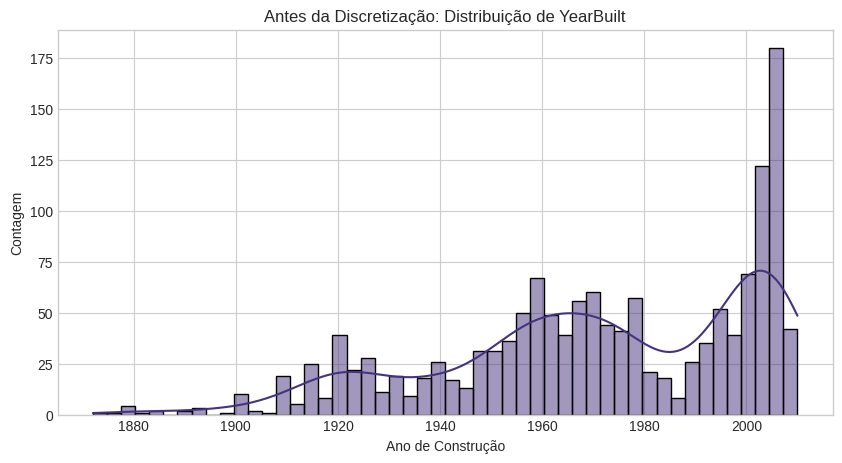

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(df['YearBuilt'], kde=True, bins=50)
plt.title('Antes da Discretização: Distribuição de YearBuilt')
plt.xlabel('Ano de Construção')
plt.ylabel('Contagem')
plt.show()

### Discretização  por largura iguais



*   Vamos dividir em *bins* de largura (valores) uniformes, exemplo: 0-10, 10-20... ou seja uma largura de 10.

*   Funciona bem com disctibuições uniformes

*   Cuidar com aplicar em distribuição com outliers, pois pode criar uma classe de baixa representatividade



IdadeCasa_Categoria
Moderna         702
Recente         486
Antiga          244
Muito Antiga     28
Name: count, dtype: int64

--- Limites dos Bins (pd.cut) ---
[3 1 2 0]
IntervalIndex([(1871.862, 1906.5], (1906.5, 1941.0], (1941.0, 1975.5],
               (1975.5, 2010.0]],
              dtype='interval[float64, right]')


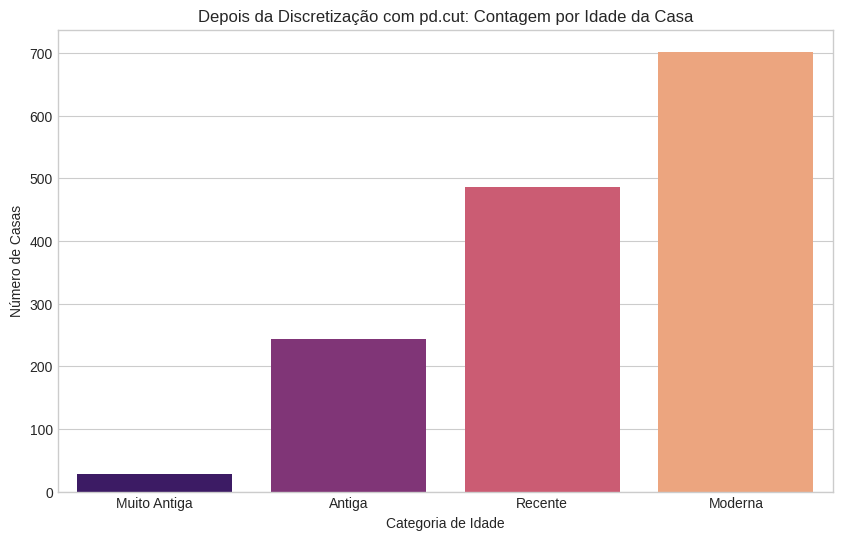

In [ ]:
# Criar uma cópia para a transformação
df_binned = df.copy()

# Aplicar o pd.cut para criar 4 categorias
# Cria bins de larguras iguais(não quantidades de elementos iguais) (ex: 0-10, 10-20, 20-30). 0 esta dentro do primeiro, o 10 pertence ao segundo
df_binned['IdadeCasa_Categoria'] = pd.cut(
    df_binned['YearBuilt'],
    bins=4, # [-np.inf, 2, 4, 12, np.inf] caso quiser eu delimitar
    labels=['Muito Antiga', 'Antiga', 'Recente', 'Moderna']
)



print(df_binned['IdadeCasa_Categoria'].value_counts())

print("\n--- Limites dos Bins (pd.cut) ---")
print(df_binned['IdadeCasa_Categoria'].cat.codes.unique())
print(pd.cut(df_binned['YearBuilt'], bins=4).cat.categories) # 34.5 anos


# Gráfico do resultado

sns.countplot(x='IdadeCasa_Categoria', data=df_binned, palette='magma')
plt.title('Depois da Discretização com pd.cut: Contagem por Idade da Casa')
plt.xlabel('Categoria de Idade')
plt.ylabel('Número de Casas')
plt.show()

### Discretização por frequência iguais
Vamos dividir em bins com o mesmo numero de observações em cada classe.
Funciona bem em distribuições desbalanceadas, lidando com os outliers.




--- Contagem por Categoria (pd.qcut) ---
IdadeCasa_Categoria
Muito Antiga    385
Moderna         364
Recente         356
Antiga          355
Name: count, dtype: int64

--- Pontos de Corte dos Bins (pd.qcut) ---
IntervalIndex([(1871.999, 1954.0], (1954.0, 1973.0], (1973.0, 2000.0],
               (2000.0, 2010.0]],
              dtype='interval[float64, right]')


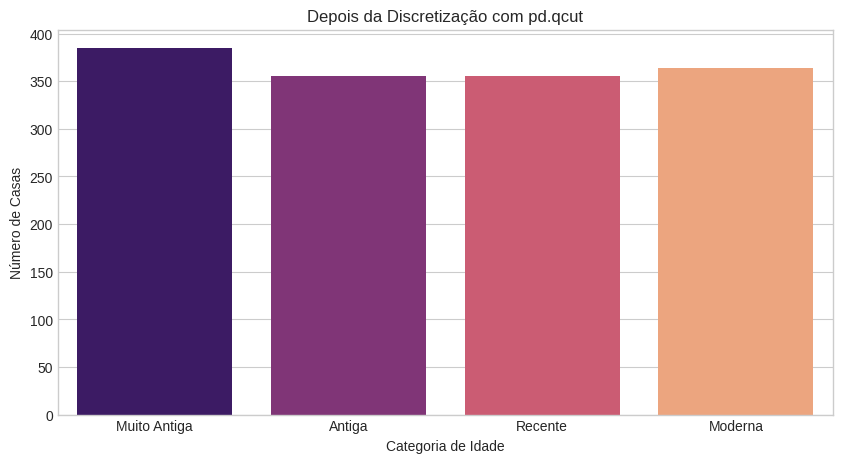

In [ ]:
# Aplicar o pd.qcut para criar 4 categorias baseadas em quartis
df_binned['IdadeCasa_Categoria'] = pd.qcut(
    df_binned['YearBuilt'],
    q=4,
    labels=['Muito Antiga', 'Antiga', 'Recente', 'Moderna']
)

print("\n--- Contagem por Categoria (pd.qcut) ---")
print(df_binned['IdadeCasa_Categoria'].value_counts())

print("\n--- Pontos de Corte dos Bins (pd.qcut) ---")
print(pd.qcut(df_binned['YearBuilt'], q=4).cat.categories)


# Gráfico do resultado
plt.figure(figsize=(10, 5))
sns.countplot(x='IdadeCasa_Categoria', data=df_binned, palette='magma')
plt.title('Depois da Discretização com pd.qcut')
plt.xlabel('Categoria de Idade')
plt.ylabel('Número de Casas')
plt.show()

### Discretização por logaritmo

Vamos agrupar por logaritmos os bins, funcina bem com distribuição assimétricas positivas. Atenção ao exemplo com o *ano de construção*.


--- Contagem por Categoria (Escala Logarítmica) ---
IdadeCasa_Categoria
Moderna         709
Recente         511
Antiga          212
Muito Antiga     27
Name: count, dtype: int64

--- Pontos de Corte Logarítmicos ---
[1872.         1905.58531634 1939.77318262 1974.5744091  2010.        ]


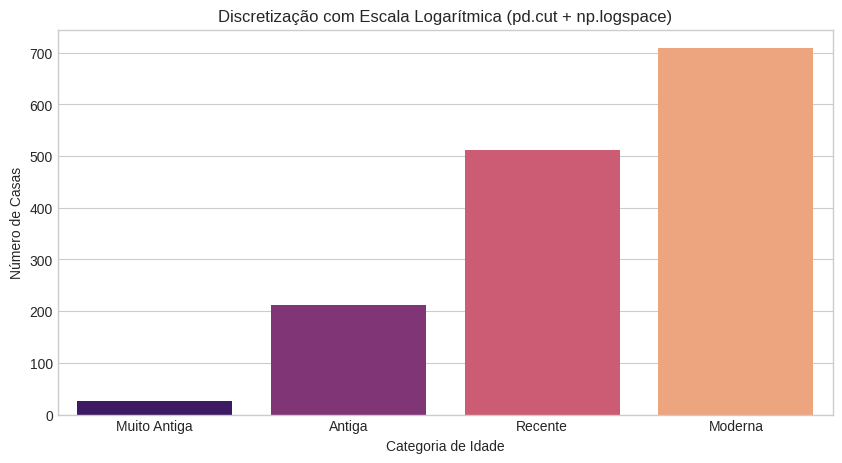

In [ ]:
# Defini os limites (min e max) dos dados originais
min_val = df_binned['YearBuilt'].min()
max_val = df_binned['YearBuilt'].max()

# Gera 5 pontos de corte em escala logarítmica (para criar 4 bins)
# Usamos np.log10 para definir o início e fim da escala
log_bins = np.logspace(np.log10(min_val), np.log10(max_val), num=5)

# Aplica o pd.cut (em vez de qcut) com os bins logarítmicos
df_binned['IdadeCasa_Categoria'] = pd.cut(
    df_binned['YearBuilt'],
    bins=log_bins,
    labels=['Muito Antiga', 'Antiga', 'Recente', 'Moderna'],
    include_lowest=True
)

print("\n--- Contagem por Categoria (Escala Logarítmica) ---")
print(df_binned['IdadeCasa_Categoria'].value_counts())

print("\n--- Pontos de Corte Logarítmicos ---")
print(log_bins)

# Gráfico do resultado
plt.figure(figsize=(10, 5))
sns.countplot(x='IdadeCasa_Categoria', data=df_binned, palette='magma')
plt.title('Discretização com Escala Logarítmica (pd.cut + np.logspace)')
plt.xlabel('Categoria de Idade')
plt.ylabel('Número de Casas')
plt.show()

Como o ano de construção apresenta uma assimetria negativa, o resulta apresentou uma classe rara (muito antiga), vamos usar a área habitável.

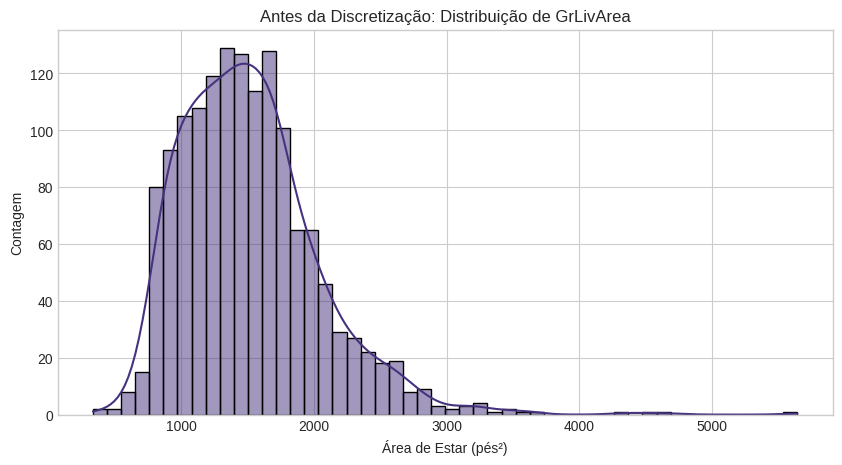

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(df['GrLivArea'], kde=True, bins=50)
plt.title('Antes da Discretização: Distribuição de GrLivArea')
plt.xlabel('Área de Estar (pés²)')
plt.ylabel('Contagem')
plt.show()


--- Contagem por Categoria (Escala Logarítmica) ---
LivAreaCasa_Categoria
Grande          797
Media           619
Muito grande     29
Pequena          13
Name: count, dtype: int64

--- Pontos de Corte Logarítmicos ---
[ 334.          677.1238649  1372.74469586 2782.98860472 5642.        ]


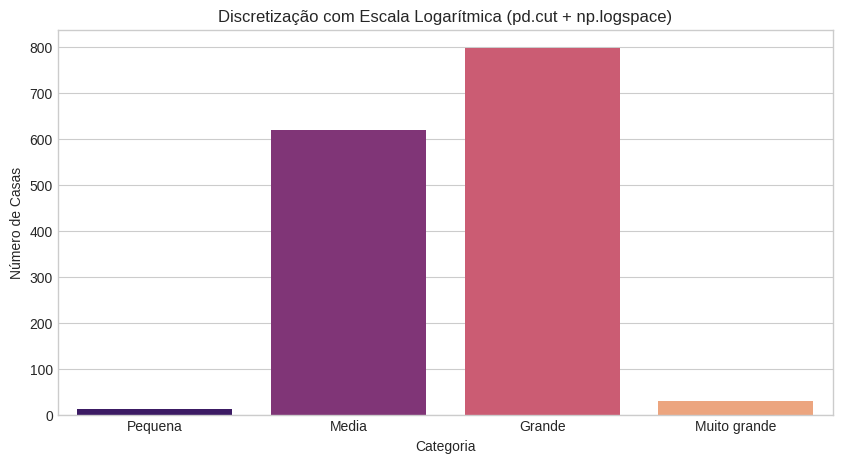

In [ ]:
#Defini os limites (min e max) dos dados originais
min_val = df_binned['GrLivArea'].min()
max_val = df_binned['GrLivArea'].max()

# Gerar 5 pontos de corte em escala logarítmica (para criar 4 bins)
# Usamos np.log10 para definir o início e fim da escala
log_bins = np.logspace(np.log10(min_val), np.log10(max_val), num=5)

# Aplica o pd.cut (em vez de qcut) com os bins logarítmicos
df_binned['LivAreaCasa_Categoria'] = pd.cut(
    df_binned['GrLivArea'],
    bins=log_bins,
    labels=['Pequena', 'Media', 'Grande', 'Muito grande'],
    include_lowest=True
)

print("\n--- Contagem por Categoria (Escala Logarítmica) ---")
print(df_binned['LivAreaCasa_Categoria'].value_counts())

print("\n--- Pontos de Corte Logarítmicos ---")
print(log_bins)

# Gráfico do resultado
plt.figure(figsize=(10, 5))
sns.countplot(x='LivAreaCasa_Categoria', data=df_binned, palette='magma')
plt.title('Discretização com Escala Logarítmica (pd.cut + np.logspace)')
plt.xlabel('Categoria' )
plt.ylabel('Número de Casas')
plt.show()


### Discretização k means



*   utilizaremos um modelo k-means (não supervisionado) para definir os pontos de corte
*   funciona muito bem quando desconhecemos o padrão dos dados. Na duvida aplique este.

*  distibrições com diversos picos se beneficiam com este metodo que cria clusters por proximidade



[1, 3, 0, 2]
--- Contagem por Categoria (K-Means) ---
Area_Categoria_KMeans
Média           522
Pequena         416
Grande          414
Muito Grande    108
Name: count, dtype: int64

--- Intervalos das Categorias K-Means (Baseado em Min/Max) ---
  - Pequena        : (334.00 a 1188.00)
  - Média          : (1190.00 a 1641.00)
  - Grande         : (1644.00 a 2291.00)
  - Muito Grande   : (2295.00 a 5642.00)


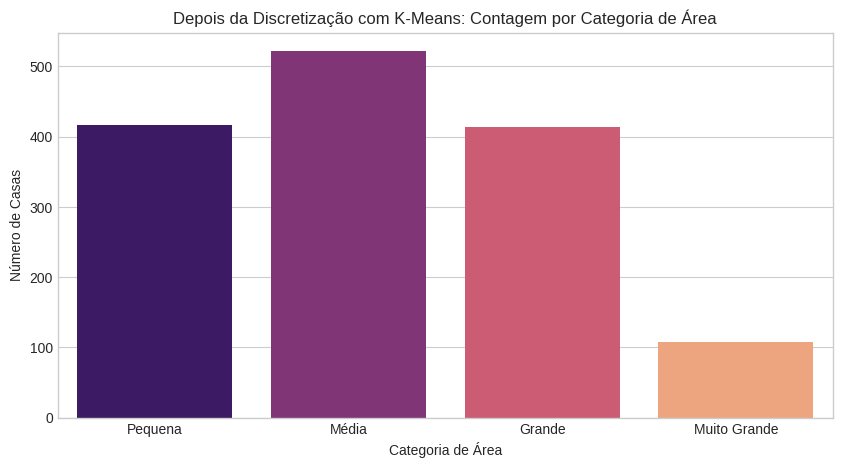

In [ ]:
from sklearn.cluster import KMeans
import numpy as np

# Preparamos os dados para o K-Means
# O algoritmo espera um array 2D como entrada (não uma lista simples como estamos entrando).
# Usamos .values.reshape(-1, 1) para transformar nossa coluna (Series 1D) nesse formato.
gr_liv_area_reshaped = df_binned['GrLivArea'].values.reshape(-1, 1) # -1 calcula o numero de linha automatica e o 1 é porque temos apenas uma variavel. Se tivessemos mais varaiveis não precisariamos entrar com reshape

# Instancia e treina o modelo K-Means
# n_clusters=4: Queremos criar 4 categorias, assim como no pd.qcut.
kmeans_model = KMeans(n_clusters=4, n_init='auto', random_state=42)

# Aplica o K-Means para obter os rótulos (labels) dos clusters
# O método .fit_predict() treina o modelo e retorna o cluster ao qual cada casa pertence.
# O resultado será um array com números [0, 1, 2, 3, 1, 0, ...], etc.
cluster_labels = kmeans_model.fit_predict(gr_liv_area_reshaped)

# Adiciona os labels numéricos brutos ao DataFrame
df_binned['Area_KMeans_Label'] = cluster_labels

# valores dos centroides
centroids = kmeans_model.cluster_centers_.flatten() # retorna unidimensional

#Cria um mapa i:centroide[i]
centroid_map = {i: centroids[i] for i in range(len(centroids))}


# ordenar os centroides pelo valor central
sorted_labels = sorted(centroid_map, key=centroid_map.get)
print(sorted_labels)

# vamos dar os nomes aos indices
category_names = ['Pequena', 'Média', 'Grande', 'Muito Grande']
label_mapping = {sorted_labels[i]: category_names[i] for i in range(len(sorted_labels))}

# Avamos aplicar a todo data frame
df_binned['Area_Categoria_KMeans'] = df_binned['Area_KMeans_Label'].map(label_mapping)

#
print("--- Contagem por Categoria (K-Means) ---")
print(df_binned['Area_Categoria_KMeans'].value_counts())

# intervalos baseados nos valores min/max de cada cluster
print("\n--- Intervalos das Categorias K-Means (Baseado em Min/Max) ---")

# Calcula min e max GrLivArea para cada cluster
cluster_intervals = df_binned.groupby('Area_KMeans_Label')['GrLivArea'].agg(['min', 'max'])

# Map para colocar os nomes
cluster_intervals['CategoryName'] = cluster_intervals.index.map(label_mapping)

# em ordem
cluster_intervals_sorted = cluster_intervals.set_index('CategoryName').loc[category_names]

# mostrar os intervalos
for category in category_names:
    min_val_cat = cluster_intervals_sorted.loc[category, 'min']
    max_val_cat = cluster_intervals_sorted.loc[category, 'max']
    print(f"  - {category:<15}: ({min_val_cat:.2f} a {max_val_cat:.2f})")

# Gráfico do resultado
plt.figure(figsize=(10, 5))
sns.countplot(x='Area_Categoria_KMeans', data=df_binned, order=category_names, palette='magma')
plt.title('Depois da Discretização com K-Means: Contagem por Categoria de Área')
plt.xlabel('Categoria de Área')
plt.ylabel('Número de Casas')
plt.show()

#### **Atividade**: vamos aplicar a discretização de k means ao dados da idade da casa.

[0, 3, 2, 1]
--- Contagem por Categoria (K-Means) ---
YearBuilt_Categoria_KMeans
Moderna         568
Recente         357
Antiga          328
Muito Antiga    207
Name: count, dtype: int64

--- Intervalos das Categorias K-Means (Baseado em Min/Max) ---
  - Muito Antiga   : (1872.00 a 1934.00)
  - Antiga         : (1935.00 a 1962.00)
  - Recente        : (1963.00 a 1986.00)
  - Moderna        : (1987.00 a 2010.00)


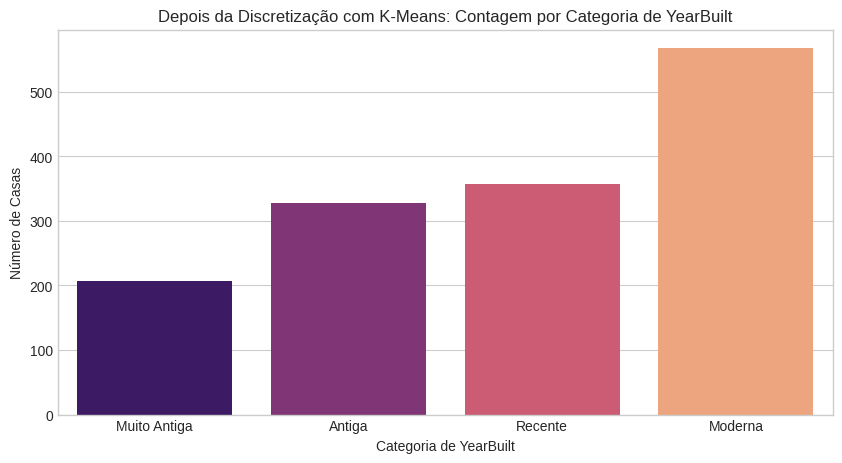

In [ ]:
# Preparar os dados para o K-Means
# O algoritmo espera um array 2D como entrada (não uma lista simples como estamos entrando).
# Usamos .values.reshape(-1, 1) para transformar nossa coluna (Series 1D) nesse formato.
YearBuilt_reshaped = df_binned['YearBuilt'].values.reshape(-1, 1) # -1 calcula o numero de linha automatica e o 1 é porque temos apenas uma variavel. Se tivessemos mais varaiveis não precisariamos entrar com reshape

# Instanciar e treinar o modelo K-Means
# n_clusters=4: Queremos criar 4 categorias, assim como no pd.qcut.
kmeans_model = KMeans(n_clusters=4, n_init='auto', random_state=42)

# Aplicar o K-Means para obter os rótulos (labels) dos clusters
# O método .fit_predict() treina o modelo e retorna o cluster ao qual cada casa pertence.
# O resultado será um array com números [0, 1, 2, 3, 1, 0, ...], etc.
cluster_labels = kmeans_model.fit_predict(YearBuilt_reshaped)

# Adicionar os labels numéricos brutos ao DataFrame
df_binned['YearBuilt_KMeans_Label'] = cluster_labels

# valores dos centroides
centroids = kmeans_model.cluster_centers_.flatten() # retorna unidimensional

#Criar um mapa i:centroide[i]
centroid_map = {i: centroids[i] for i in range(len(centroids))}


# ordenar os centroides pelo valor central
sorted_labels = sorted(centroid_map, key=centroid_map.get)
print(sorted_labels)

# vamos dar os nomes aos indices
category_names = ['Muito Antiga', 'Antiga', 'Recente', 'Moderna']
label_mapping = {sorted_labels[i]: category_names[i] for i in range(len(sorted_labels))}

# Avamos aplicar a todo data frame
df_binned['YearBuilt_Categoria_KMeans'] = df_binned['YearBuilt_KMeans_Label'].map(label_mapping)

#
print("--- Contagem por Categoria (K-Means) ---")
print(df_binned['YearBuilt_Categoria_KMeans'].value_counts())

# Exibir os intervalos baseados nos valores min/max de cada cluster
print("\n--- Intervalos das Categorias K-Means (Baseado em Min/Max) ---")

#calcular o maximo e o minimo
cluster_intervals = df_binned.groupby('YearBuilt_KMeans_Label')['YearBuilt'].agg(['min', 'max'])

# Mapeamento
cluster_intervals['CategoryName'] = cluster_intervals.index.map(label_mapping)

## em ordem
cluster_intervals_sorted = cluster_intervals.set_index('CategoryName').loc[category_names]

# mostrar os intervalos
for category in category_names:
    min_val_cat = cluster_intervals_sorted.loc[category, 'min']
    max_val_cat = cluster_intervals_sorted.loc[category, 'max']
    print(f"  - {category:<15}: ({min_val_cat:.2f} a {max_val_cat:.2f})")

# Gráfico do resultado
plt.figure(figsize=(10, 5))
sns.countplot(x='YearBuilt_Categoria_KMeans', data=df_binned, order=category_names, palette='magma')
plt.title('Depois da Discretização com K-Means: Contagem por Categoria de YearBuilt')
plt.xlabel('Categoria de YearBuilt')
plt.ylabel('Número de Casas')
plt.show()

Temos a ferramenta `kBinsDiscretizer` que permite criarmos diretamente  os bins numericos de forma ordinal.

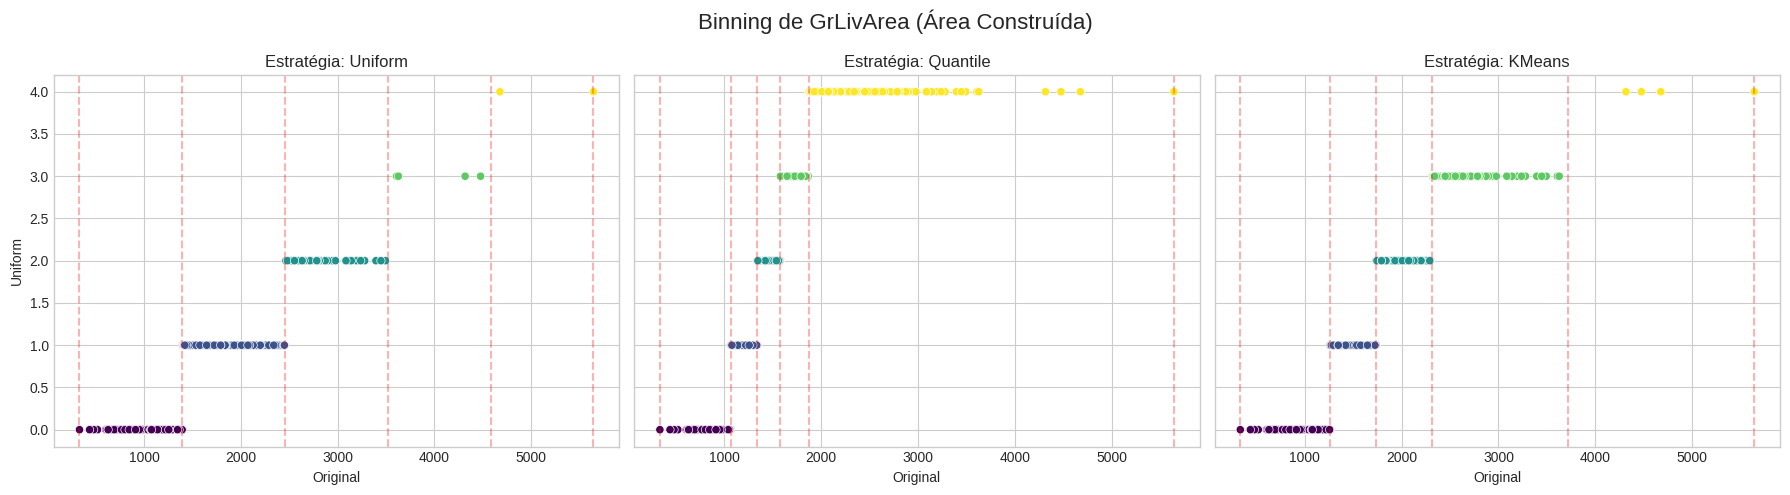


--- Limites dos Bins (Edges) ---
Uniforme: [ 334.  1395.6 2457.2 3518.8 4580.4 5642. ]
Quantil:  [ 334.  1066.6 1339.  1578.  1869.  5642. ]
kmeans:  [ 334.  1263.  1737.8 2311.3 3717.  5642. ]


In [ ]:

from sklearn.preprocessing import KBinsDiscretizer

# Preparação dos dados
# Usando GrLivArea para demonstrar o agrupamento por faixas de tamanho
X_area = df[['GrLivArea']].dropna()

# Configurar os 3 tipos de Binning
# n_bins=5: criamos 5 faixas de tamanho de casa
# encode='ordinal': retorna 0, 1, 2, 3, 4 (fácil de visualizar)
est_uniform = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='uniform')
est_quantile = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')
est_kmeans = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='kmeans')

# Aplicar as transformações
df_bin = pd.DataFrame({
    'Original': X_area['GrLivArea'],
    'Uniform': est_uniform.fit_transform(X_area).flatten(),
    'Quantile': est_quantile.fit_transform(X_area).flatten(),
    'KMeans': est_kmeans.fit_transform(X_area).flatten()
})

# Visualização
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

strategies = ['Uniform', 'Quantile', 'KMeans']
for i, s in enumerate(strategies):
    sns.scatterplot(data=df_bin, x='Original', y=s, ax=axes[i], hue=s, palette='viridis', legend=False)
    axes[i].set_title(f'Estratégia: {s}')

    # Adicionar as linhas que dividem os bins (edges)
    if s == 'Uniform': edges = est_uniform.bin_edges_[0]
    elif s == 'Quantile': edges = est_quantile.bin_edges_[0]
    else: edges = est_kmeans.bin_edges_[0]

    for edge in edges:
        axes[i].axvline(edge, color='red', linestyle='--', alpha=0.3)

plt.suptitle('Binning de GrLivArea (Área Construída)', fontsize=16)
plt.tight_layout()
plt.show()

# Exemplo prático para a lousa
print("\n--- Limites dos Bins (Edges) ---")
print(f"Uniforme: {est_uniform.bin_edges_[0].round(1)}")
print(f"Quantil:  {est_quantile.bin_edges_[0].round(1)}")
print(f"kmeans:  {est_kmeans.bin_edges_[0].round(1)}")


## **Decodificação** (Encoding):
Converter variáveis textuais (categóricas) em um formato numérico para que os algoritmos de machine learning possam processá-las. Passo obrigatorio em praticamente todos os processos.



*   One-hot Enconding: Cria novas colunas binárias (0 ou 1) para cada categoria de uma variável. É o método mais comum e seguro, pois não cria uma relação de ordem artificial.







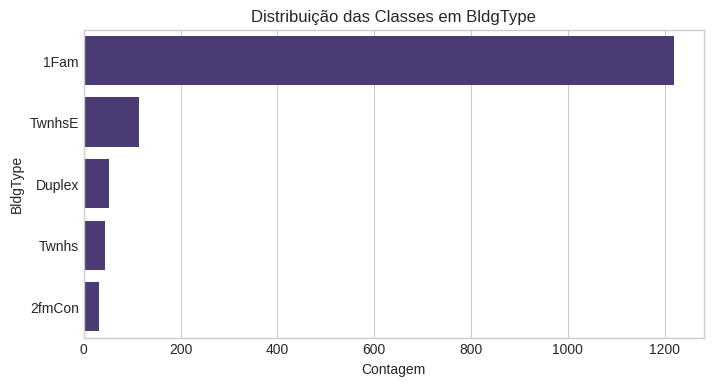

In [ ]:
# Visualizando a distribuição das classes para 'BldgType'
plt.figure(figsize=(8, 4))
sns.countplot(data=df, y='BldgType', order = df['BldgType'].value_counts().index)
plt.title('Distribuição das Classes em BldgType')
plt.xlabel('Contagem')
plt.ylabel('BldgType')
plt.show()

In [ ]:
# Criar uma cópia para a transformação
df_encoded = df.copy()

# Aplicar pd.get_dummies
dummies = pd.get_dummies(df_encoded['BldgType'], prefix='TipoMoradia', dtype=int) # podemos adicionar um prefixo

# Juntar os dummies ao DataFrame e remover a coluna original
df_encoded = pd.concat([df_encoded.drop('BldgType', axis=1), dummies], axis=1)

print("\n--- Depois do One-Hot Encoding ---")
# Mostrar as novas colunas criadas
print(df_encoded[['TipoMoradia_1Fam', 'TipoMoradia_2fmCon', 'TipoMoradia_Duplex', 'TipoMoradia_Twnhs', 'TipoMoradia_TwnhsE']].head())


--- Depois do One-Hot Encoding ---
   TipoMoradia_1Fam  TipoMoradia_2fmCon  TipoMoradia_Duplex  \
0                 1                   0                   0   
1                 1                   0                   0   
2                 1                   0                   0   
3                 1                   0                   0   
4                 1                   0                   0   

   TipoMoradia_Twnhs  TipoMoradia_TwnhsE  
0                  0                   0  
1                  0                   0  
2                  0                   0  
3                  0                   0  
4                  0                   0  


O problema destas técnicas é que acabamos por gerar muitas colunas caso tivermos  muitas categorias, para isso temos algumas opções (podemos encontrar uma vasta gama de outros metyodos no pacote [category_encoders](https://contrib.scikit-learn.org/category_encoders/))

Destacamos o uso do *target encoder*, que é substituir a categoria pelo valor médio da variável alvo das observações dentro desta classe.

In [ ]:
from sklearn.preprocessing import TargetEncoder

# O parâmetro 'smooth' controla a suavização.
# Se definido como 'auto', ele usa uma estimativa bayesiana.
# 'target_type' ajuda o sklearn a entender se é regressão (continuous) ou classificação. pode deixar "auto"
encoder_sk = TargetEncoder(smooth='auto', target_type='continuous')


# O Scikitlearn espera que a entrada X seja 2D (mesmo para uma coluna)
# E o y seja um array 1D
X_cat = df[['Neighborhood']]
y = df[target]


neighborhood_encoded = encoder_sk.fit_transform(X_cat, y)

df_aula = pd.DataFrame({
    'Bairro_Original': df['Neighborhood'],
    'Encoded_Sklearn': neighborhood_encoded.flatten()
})


print(df_aula.drop_duplicates().head(10))

  Bairro_Original  Encoded_Sklearn
0         CollgCr    199495.485462
1         Veenker    238169.936669
2         CollgCr    194903.775325
3         Crawfor    216252.477433
4         NoRidge    331582.010121
5         Mitchel    155581.976609
6         Somerst    214506.535491
7          NWAmes    184055.479354
8         OldTown    125201.466841
9         BrkSide    124323.911956


note que usamos um valor de *smooting* para suavizar os valores médios, afim de não deixar que bairros com pouco representatividade tenham o valor da exato de suas medias, deslocando-os para o valor médio geral.

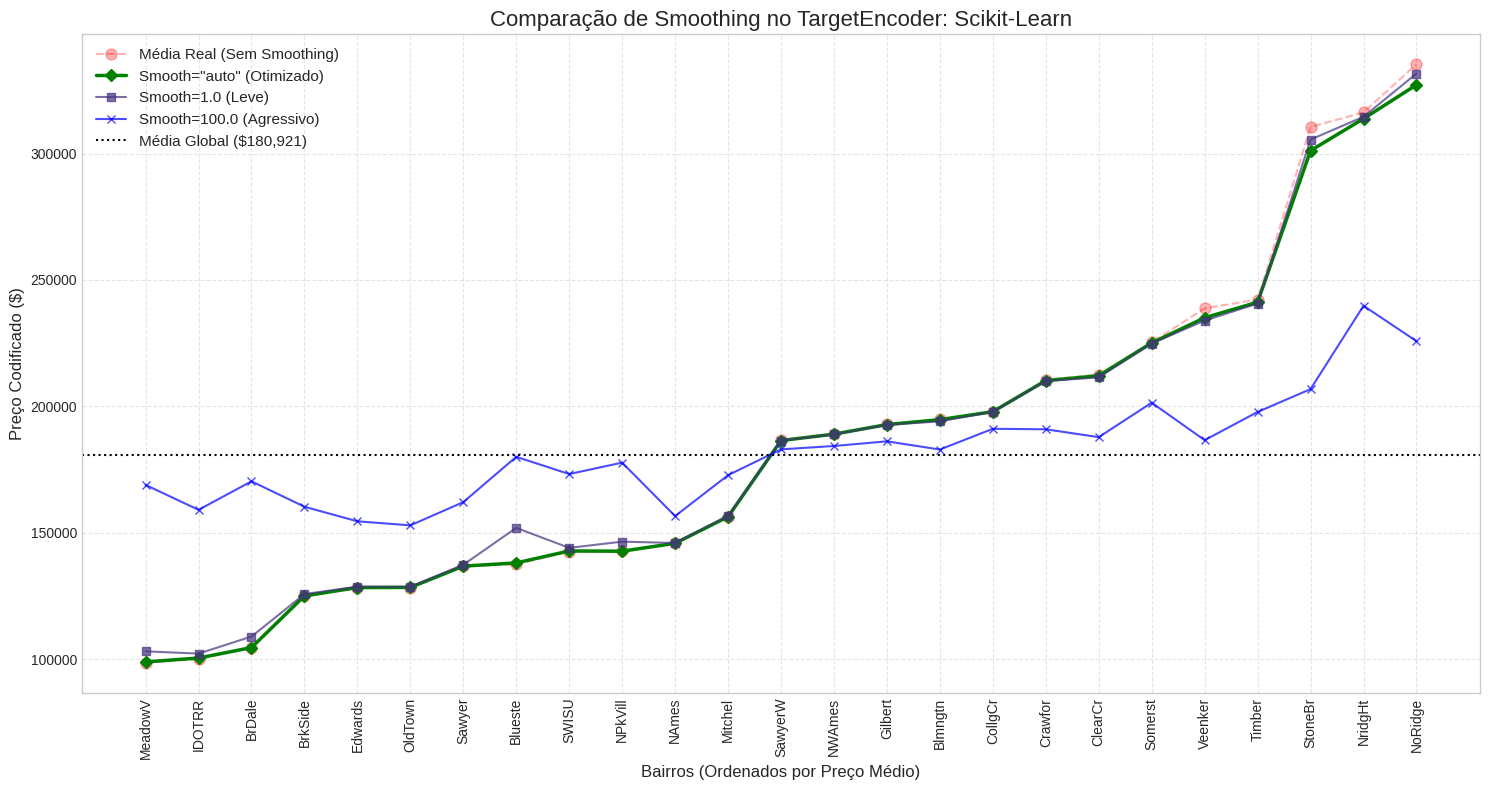

In [ ]:

X = df[['Neighborhood']]
y = df['SalePrice']
media_global = y.mean()


# smooth='auto': Decisão estatística baseada na variância.
# smooth=1.0: Pouca suavização (confia muito no dado do bairro).
# smooth=100.0: Muita suavização (confia mais na média da cidade).
enc_auto = TargetEncoder(smooth='auto', target_type='continuous', random_state=42)
enc_small = TargetEncoder(smooth=1.0, target_type='continuous', random_state=42)
enc_large = TargetEncoder(smooth=100.0, target_type='continuous', random_state=42)

# Ajustando (Fit)
enc_auto.fit(X, y)
enc_small.fit(X, y)
enc_large.fit(X, y)

# PREPARAÇÃO DOS DADOS PARA O GRÁFICO ---
# Criamos um dataframe com bairros únicos para comparar as transformações
bairros_stats = df.groupby('Neighborhood').agg(
    Contagem=('SalePrice', 'count'),
    Media_Real=('SalePrice', 'mean')
).reset_index()

# Aplicando as transformações nos bairros únicos
X_unicos = bairros_stats[['Neighborhood']]
bairros_stats['Auto'] = enc_auto.transform(X_unicos)
bairros_stats['Small_1'] = enc_small.transform(X_unicos)
bairros_stats['Large_100'] = enc_large.transform(X_unicos)

# Ordenar por preço médio para facilitar a leitura do gráfico
bairros_stats = bairros_stats.sort_values('Media_Real')

# Gráficos
plt.figure(figsize=(15, 8))

# Média Real
plt.plot(bairros_stats['Neighborhood'], bairros_stats['Media_Real'],
         'ro--', label='Média Real (Sem Smoothing)', alpha=0.3, markersize=8)

# Linha do Smooth Auto
plt.plot(bairros_stats['Neighborhood'], bairros_stats['Auto'],
         'gD-', label='Smooth="auto" (Otimizado)', linewidth=2.5)

# Linha do Smooth Small
plt.plot(bairros_stats['Neighborhood'], bairros_stats['Small_1'],
         's-', label='Smooth=1.0 (Leve)', alpha=0.7)

# Linha do Smooth Large
plt.plot(bairros_stats['Neighborhood'], bairros_stats['Large_100'],
         'bx-', label='Smooth=100.0 (Agressivo)', alpha=0.7)

# Linha de Referência: Média Global
plt.axhline(media_global, color='black', linestyle=':', label=f'Média Global (${media_global:,.0f})')

# Títulos e Legendas
plt.title('Comparação de Smoothing no TargetEncoder: Scikit-Learn', fontsize=16)
plt.xlabel('Bairros (Ordenados por Preço Médio)', fontsize=12)
plt.ylabel('Preço Codificado ($)', fontsize=12)
plt.xticks(rotation=90)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


*  *Codificador ordinal (OrdinalEncoder)*: Converte categorias em números inteiros (0, 1, 2, ...).
  **Devendo  ser usado apenas quando as categorias têm uma ordem intrínseca e clara** (ex: "ruim" < "médio" < "bom").


In [ ]:
# Definir a ordem correta das categorias, de pior para melhor
ordem_lareira = ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'] # None, Poor, Fair, Typical, Good, Excellent

print("--- Antes do Ordinal Encoding ---")
print(df['FireplaceQu'].value_counts().reindex(ordem_lareira))

from sklearn.preprocessing import OrdinalEncoder

# Instanciar o encoder com a ordem definida
ordinal_encoder = OrdinalEncoder(categories=[ordem_lareira])

# Aplicar a transformação
df_encoded['FireplaceQu_Ordinal'] = ordinal_encoder.fit_transform(df_encoded[['FireplaceQu']])

print("\n--- Depois do Ordinal Encoding ---")
print(df_encoded[['FireplaceQu', 'FireplaceQu_Ordinal']].sample(10))

--- Antes do Ordinal Encoding ---
FireplaceQu
None    690
Po       20
Fa       33
TA      313
Gd      380
Ex       24
Name: count, dtype: int64

--- Depois do Ordinal Encoding ---
     FireplaceQu  FireplaceQu_Ordinal
1234        None                  0.0
1435          Gd                  4.0
822           Gd                  4.0
955         None                  0.0
989         None                  0.0
946           TA                  3.0
784           Gd                  4.0
1067        None                  0.0
1074        None                  0.0
654           TA                  3.0


* Transformar categorias em numerico por meio da fatorização, só a titulo de curiosidade.



In [ ]:
# fatorização
pd.factorize(df['Neighborhood'])#[0]


(array([ 0,  1,  0, ...,  2, 11, 15]),
 Index(['CollgCr', 'Veenker', 'Crawfor', 'NoRidge', 'Mitchel', 'Somerst',
        'NWAmes', 'OldTown', 'BrkSide', 'Sawyer', 'NridgHt', 'NAmes', 'SawyerW',
        'IDOTRR', 'MeadowV', 'Edwards', 'Timber', 'Gilbert', 'StoneBr',
        'ClearCr', 'NPkVill', 'Blmngtn', 'BrDale', 'SWISU', 'Blueste'],
       dtype='object'))

* Transformação de ciclo: deve ser usada para demostrar que existe um ciclo na relação númerica ao modelo. Por exemplo, entre meses, dia da semana, horas: depois do mês 12 retornamos ao mes 1, como ensinar ao modelo esse padrão?

vamos decompor o nosso valor em termos de duas funções de seno e cosseno, gerando duas novas variaveis que juntas daram ao modelo a capacidade de reconhecer um ciclo.

   MoSold    Mo_sin    Mo_cos
0       2  0.500000  0.866025
1       5  0.866025 -0.500000
2       9 -0.866025 -0.500000
3       2  0.500000  0.866025
4      12 -0.500000  0.866025


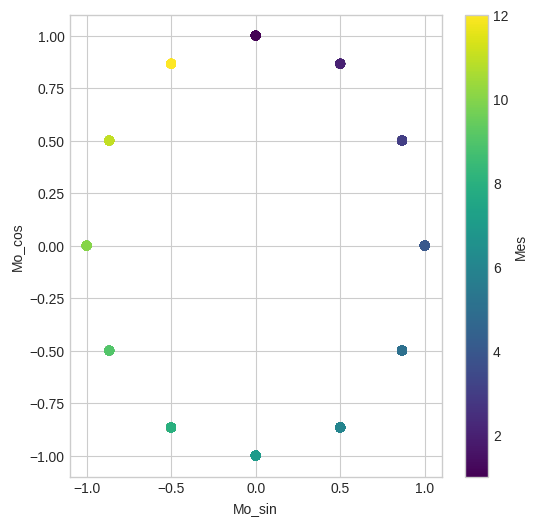

In [ ]:
# mes de venda
df_ames_cycle = df_original[['MoSold', 'SalePrice']].copy()

# vamos aplicar o ciclo
df_ames_cycle['Mo_sin'] = np.sin(2 * np.pi * (df_ames_cycle['MoSold']-1) / 12)
df_ames_cycle['Mo_cos'] = np.cos(2 * np.pi * (df_ames_cycle['MoSold']-1) / 12)


print(df_ames_cycle[['MoSold', 'Mo_sin', 'Mo_cos']].head())

# Visualiza
plt.figure(figsize=(6, 6))
plt.scatter(df_ames_cycle['Mo_sin'], df_ames_cycle['Mo_cos'], c=df_ames_cycle['MoSold'], cmap='viridis')

plt.xlabel('Mo_sin')
plt.ylabel('Mo_cos')
plt.colorbar(label='Mes')
plt.grid(True)
plt.show()

##**Transformação para Correção de Assimetria**:  
Muitas variáveis em datasets do mundo real não seguem uma distribuição normal (em forma de sino). Elas frequentemente possuem uma "cauda" longa para um dos lados, o que chamamos de assimetria (skewness). Uma assimetria positiva (à direita) significa uma cauda longa de valores altos, enquanto uma assimetria negativa (à esquerda) indica uma cauda longa de valores baixos.

Modelos lineares, em particular, se beneficiam enormemente quando as variáveis são mais simétricas. As transformações de potência, como Log, Box-Cox e Yeo-Johnson, são projetadas para comprimir essas caudas longas e tornar a distribuição da variável mais "normal".

--- Diagnóstico Quantitativo ---
Coeficiente de Assimetria Original de 'GrLivArea': 1.3666

--- Diagnóstico Visual 'Antes' da Transformação ---


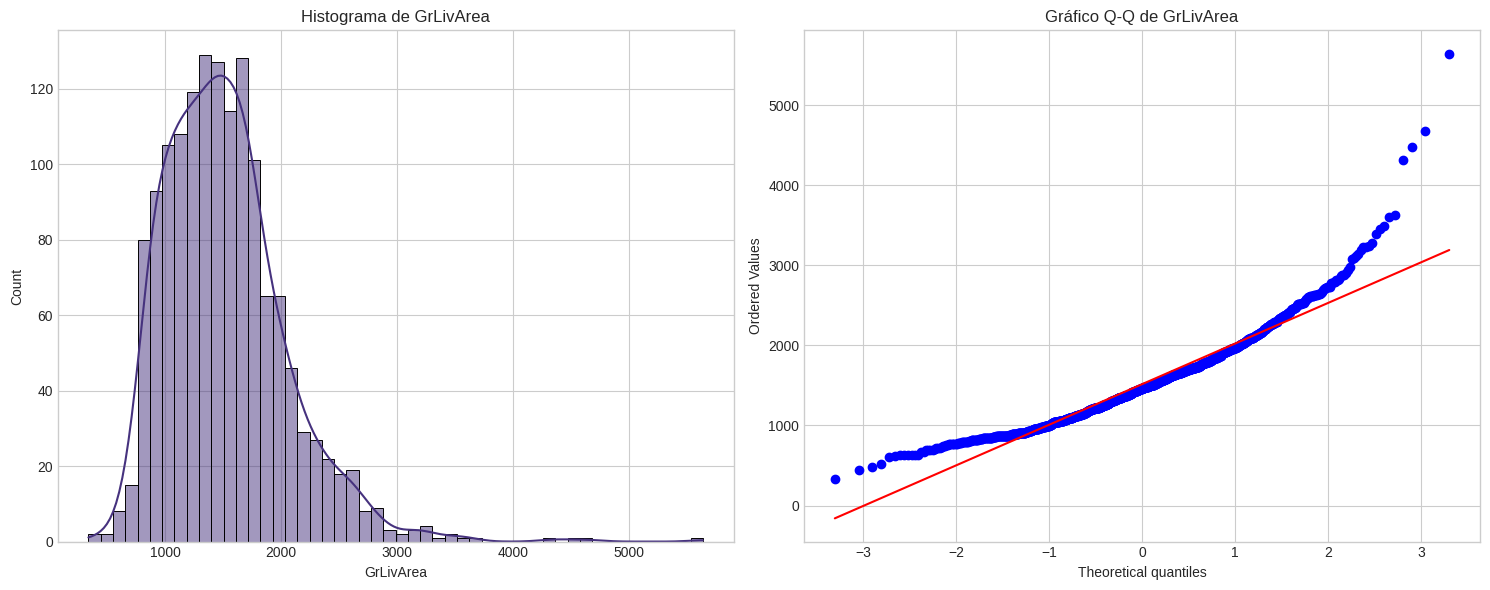

In [ ]:
# Importar bibliotecas adicionais necessárias
import scipy.stats as stats

# Carregar e preparar os dados novamente
from sklearn.datasets import fetch_openml
house_prices = fetch_openml(name="house_prices", as_frame=True)
df_full = house_prices.frame
df_transform = df_full[['GrLivArea']].copy().dropna()

# Calcular a assimetria
skew_original = df_transform['GrLivArea'].skew()
print(f"--- Diagnóstico Quantitativo ---")
print(f"Coeficiente de Assimetria Original de 'GrLivArea': {skew_original:.4f}")

# Função para plotar os diagnósticos
def plotar_diagnostico_distribuicao(df, coluna):
    plt.figure(figsize=(15, 6))

    # Histograma e KDE
    plt.subplot(1, 2, 1)
    sns.histplot(df[coluna], kde=True, bins=50)
    plt.title(f'Histograma de {coluna}')

    # Gráfico Q-Q
    plt.subplot(1, 2, 2)
    stats.probplot(df[coluna], dist="norm", plot=plt)
    plt.title(f'Gráfico Q-Q de {coluna}')

    plt.tight_layout()
    plt.show()

print("\n--- Diagnóstico Visual 'Antes' da Transformação ---")
plotar_diagnostico_distribuicao(df_transform, 'GrLivArea')

* Transformação Logarítmica: A função logarítmica cresce muito lentamente, o que a torna excelente para "comprimir" valores muito altos e reduzir a caudas a direita. Usamos `np.log1p`, que calcula *log(1 + x)*, para evitar erros caso a variável contenha zeros.

--- Resultado da Transformação Logarítmica ---
Coeficiente de Assimetria após Log: -0.0061

--- Diagnóstico Visual 'Depois' da Transformação Logarítmica ---


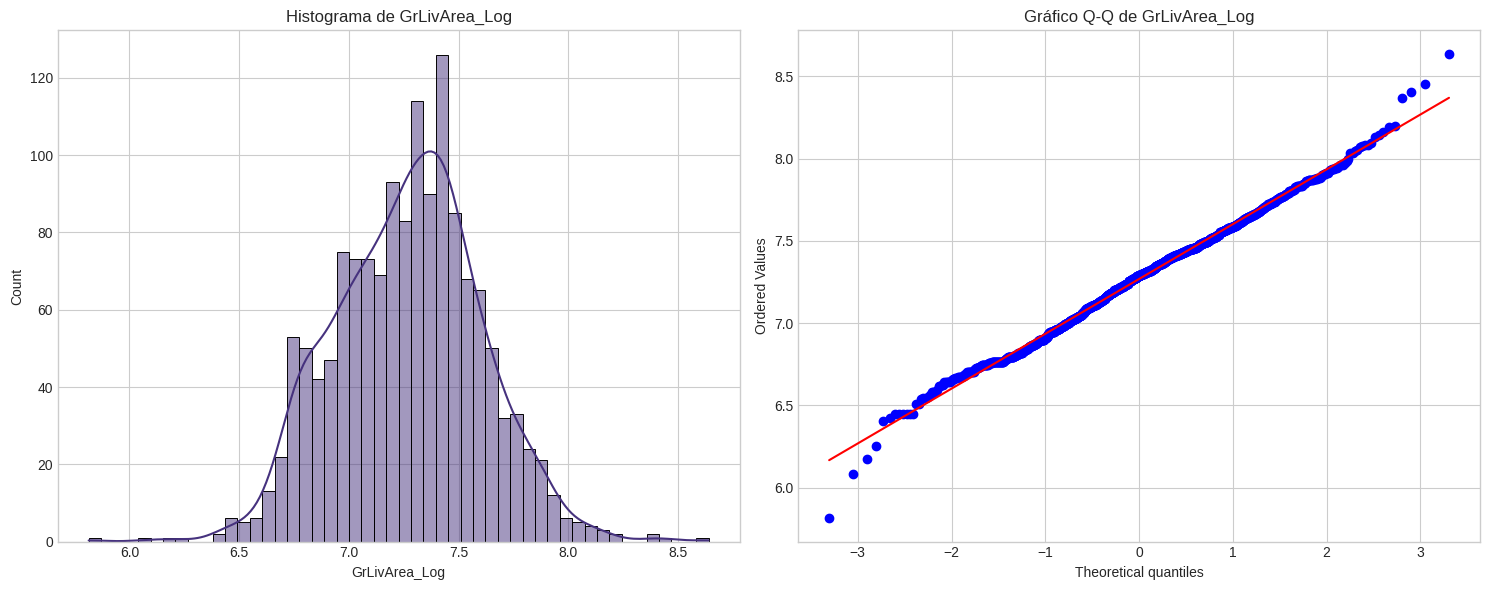

In [ ]:
# Aplicar a transformação logarítmica
df_transform['GrLivArea_Log'] = np.log1p(df_transform['GrLivArea'])

skew_log = df_transform['GrLivArea_Log'].skew()
print(f"--- Resultado da Transformação Logarítmica ---")
print(f"Coeficiente de Assimetria após Log: {skew_log:.4f}")

print("\n--- Diagnóstico Visual 'Depois' da Transformação Logarítmica ---")
plotar_diagnostico_distribuicao(df_transform, 'GrLivArea_Log')

 *  Transformação Box-Cox
Conceito: A transformação Box-Cox é uma técnica mais geral que encontra, através de um processo de otimização, o melhor expoente (λ) para aplicar aos dados para torná-los o mais normal possível. A fórmula é y(λ)=
λ
(x^
λ
 −1)
​
 . Importante: Box-Cox só funciona para dados estritamente positivos ( > 0).

--- Resultado da Transformação Box-Cox ---
Lambda ótimo encontrado: 0.0063
Coeficiente de Assimetria após Box-Cox: 0.0002

--- Diagnóstico Visual 'Depois' da Transformação Box-Cox ---


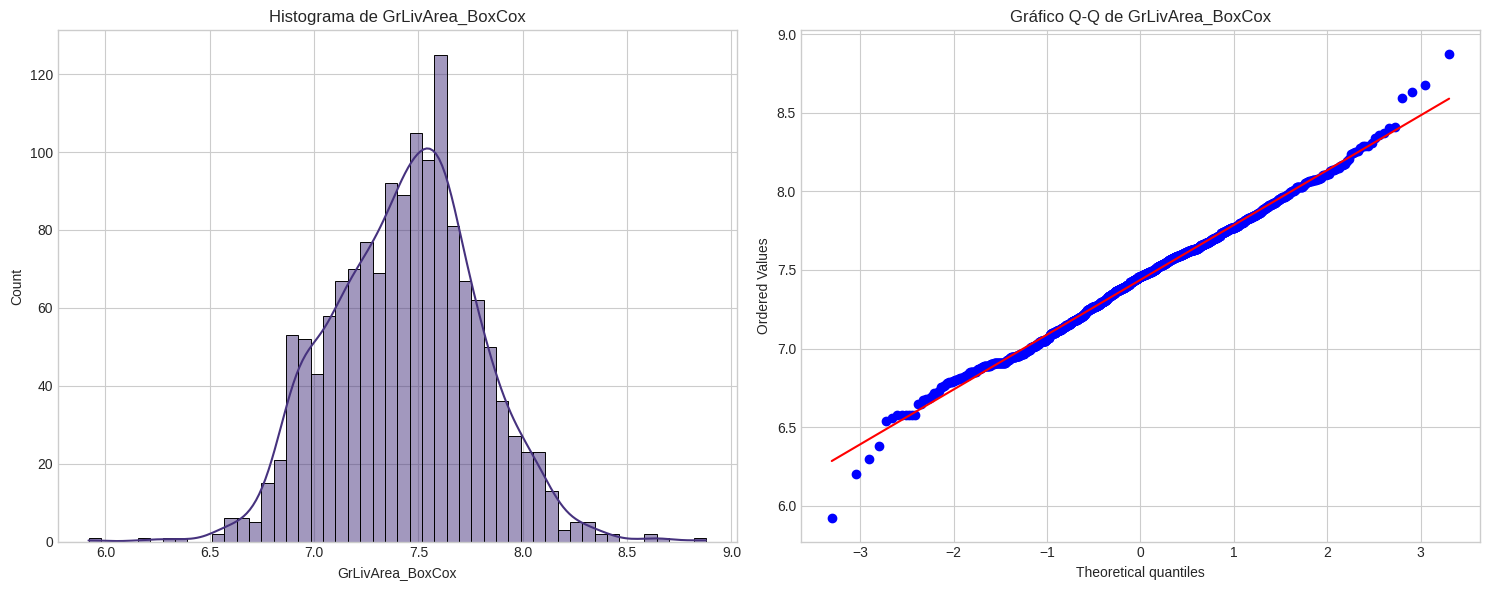

In [ ]:
from scipy.stats import boxcox

# A função boxcox retorna os dados transformados e o lambda ótimo encontrado
df_transform['GrLivArea_BoxCox'], lambda_otimo = boxcox(df_transform['GrLivArea'])

skew_boxcox = df_transform['GrLivArea_BoxCox'].skew()
print(f"--- Resultado da Transformação Box-Cox ---")
print(f"Lambda ótimo encontrado: {lambda_otimo:.4f}")
print(f"Coeficiente de Assimetria após Box-Cox: {skew_boxcox:.4f}")

print("\n--- Diagnóstico Visual 'Depois' da Transformação Box-Cox ---")
plotar_diagnostico_distribuicao(df_transform, 'GrLivArea_BoxCox')

* Transformação Yeo-Johnson: A transformação de Yeo-Johnson é uma extensão da Box-Cox. Sua grande vantagem é que funciona com dados que incluem valores zero e negativos, o que a torna a escolha mais robusta e geral. Em scikit-learn ela é implementada pelo `PowerTransformer`.

--- Resultado da Transformação Yeo-Johnson ---
Lambda ótimo encontrado: 0.0055
Coeficiente de Assimetria após Yeo-Johnson: 0.0002

--- Diagnóstico Visual 'Depois' da Transformação Yeo-Johnson ---


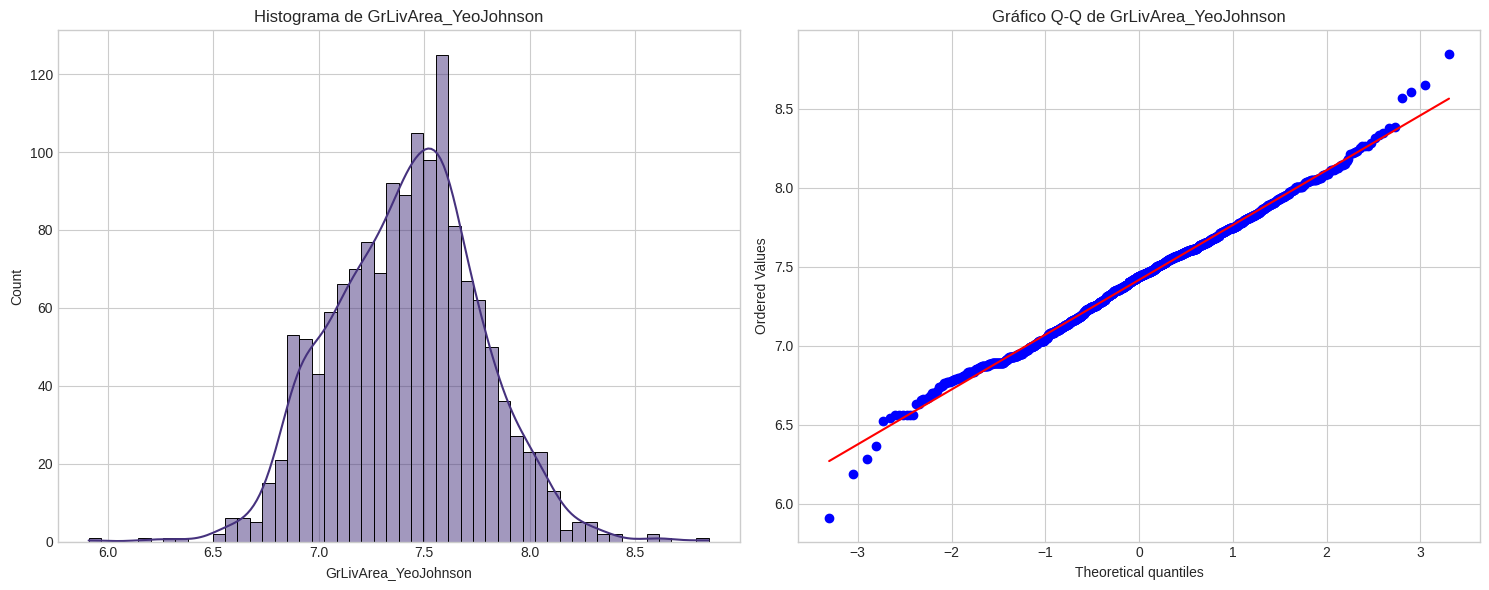

In [ ]:
from sklearn.preprocessing import PowerTransformer

# Instanciar o transformador.
# standardize=False para vermos apenas o efeito da mudança de forma, sem o scaling.
power_transformer = PowerTransformer(method='yeo-johnson', standardize=False)

# O transformador do sklearn espera um array 2D, por isso os colchetes duplos
grlivarea_reshaped = df_transform[['GrLivArea']].values
df_transform['GrLivArea_YeoJohnson'] = power_transformer.fit_transform(grlivarea_reshaped)

skew_yj = df_transform['GrLivArea_YeoJohnson'].skew()
print(f"--- Resultado da Transformação Yeo-Johnson ---")
# O lambda pode ser acessado no atributo .lambdas_
print(f"Lambda ótimo encontrado: {power_transformer.lambdas_[0]:.4f}")
print(f"Coeficiente de Assimetria após Yeo-Johnson: {skew_yj:.4f}")


print("\n--- Diagnóstico Visual 'Depois' da Transformação Yeo-Johnson ---")
plotar_diagnostico_distribuicao(df_transform, 'GrLivArea_YeoJohnson')

classes com pouco representatividade podem ser transformadas para uma classe particular, trasendo mais representação a essas observações.

--- antes ---
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

--- categorias baixas 1.00%  ---
['Veenker', 'NPkVill', 'Blueste']

--- depois ---
Neighborhood_Grouped
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Other       22
MeadowV     17
Blmngtn     17
BrDale      16
Name: count, dtype: int64


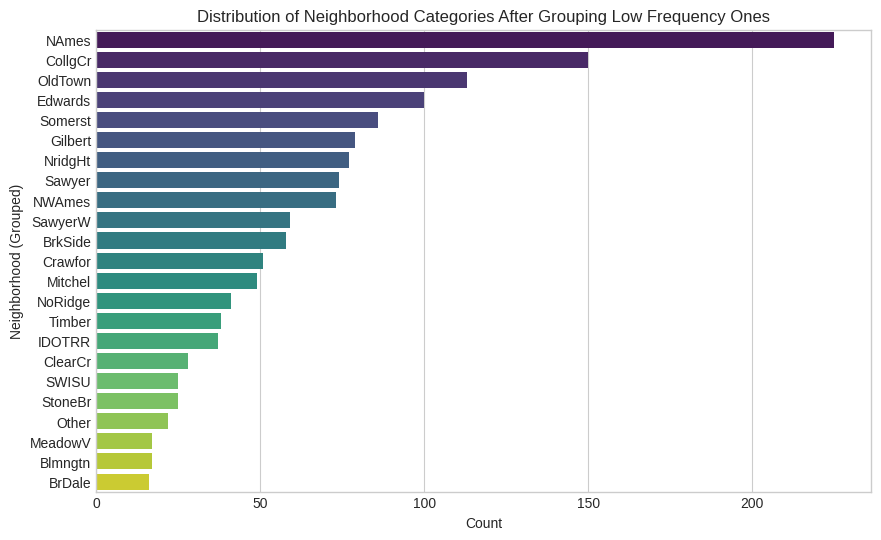

In [ ]:
# varaiveis categoricas com categorias de pouca representação podem ser trasnformadas em "outros"
df_grouped = df.copy()


# contar as categorias de 'Neighborhood'
print("--- antes ---")
print(df_grouped['Neighborhood'].value_counts())

# definir um ponto de corte
threshold = 0.01 * len(df_grouped) # menor que 1% de representação

# identificar as classes pequenas
low_frequency_categories = df_grouped['Neighborhood'].value_counts()[df_grouped['Neighborhood'].value_counts() < threshold].index.tolist()

print(f"\n--- categorias baixas {threshold/len(df_grouped):.2%}  ---")
print(low_frequency_categories)

# Replace das catagorias de baixa frequencia por  'Other'
df_grouped['Neighborhood_Grouped'] = df_grouped['Neighborhood'].replace(low_frequency_categories, 'Other')

print("\n--- depois ---")
print(df_grouped['Neighborhood_Grouped'].value_counts())

#
plt.figure(figsize=(10, 6))
sns.countplot(data=df_grouped, y='Neighborhood_Grouped', order = df_grouped['Neighborhood_Grouped'].value_counts().index, palette='viridis')
plt.title('Distribution of Neighborhood Categories After Grouping Low Frequency Ones')
plt.xlabel('Count')
plt.ylabel('Neighborhood (Grouped)')
plt.show()

## Passo 4:  Padronização e Escalonamento (Scaling)
Em Ciência de Dados, um "número" não é apenas um valor isolado, mas uma coordenada em um espaço multidimensional. O desafio surge quando tentamos comparar variáveis com naturezas e escalas distintas. Por exemplo: como o modelo deve processar a Idade de uma casa (0 a 100 anos) comparada à sua Área (50 a 5.000 m²)?

Se não ajustarmos essas escalas, o algoritmo sofrerá de Viés de Magnitude.
Ajustar essas magnitudes é essencial para modelos sensíveis à distância, como SVM, KNN e Regressão com Regularização (Ridge, Lasso). Otimizações por gradiente descentes em Redes neurais tambem são afetados

--- Antes do Scaling (Estatísticas) ---
             LotArea    GrLivArea
count    1460.000000  1460.000000
mean    10516.828082  1515.463699
std      9981.264932   525.480383
min      1300.000000   334.000000
25%      7553.500000  1129.500000
50%      9478.500000  1464.000000
75%     11601.500000  1776.750000
max    215245.000000  5642.000000


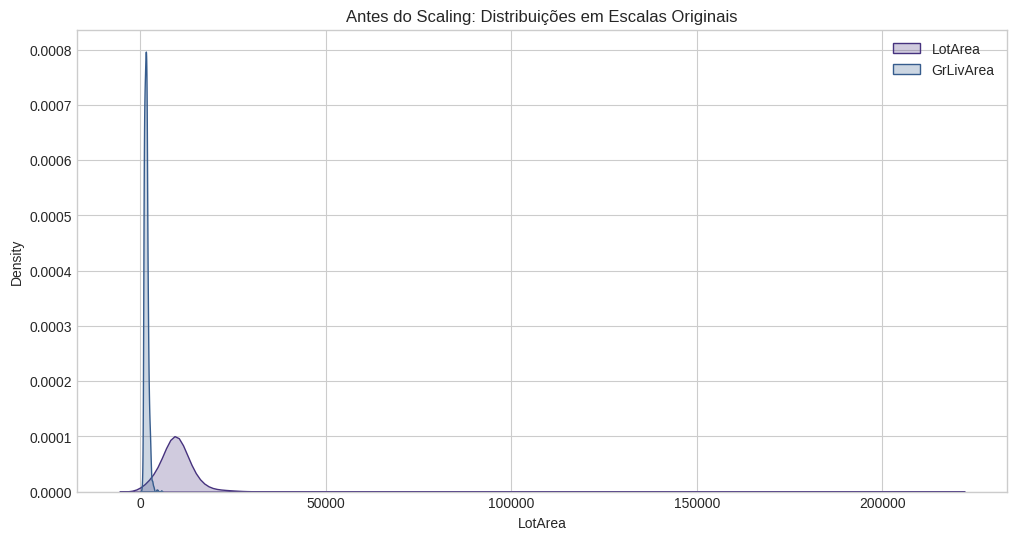

In [ ]:
# note que a area abiavel é muito diferente da area total, como comparar?
print("--- Antes do Scaling (Estatísticas) ---")
print(df[['LotArea', 'GrLivArea']].describe())

# Gráfico para visualizar as distribuições e escalas
plt.figure(figsize=(12, 6))
sns.kdeplot(data=df, x='LotArea', label='LotArea', fill=True)
sns.kdeplot(data=df, x='GrLivArea', label='GrLivArea', fill=True)
plt.title('Antes do Scaling: Distribuições em Escalas Originais')
plt.legend()
plt.show()

### Padronização por z-score (standardScaler)
A padronização reescala os dados para que possuam média 0 e desvio padrão 1. É a técnica mais indicada para algoritmos que assumem uma distribuição normal (Gaussiana). Essencial para SVM, Regressão Linear e Logística.

$$z = \frac{x - \mu}{\sigma}$$

$x$: Valor original.

$\mu$: Média aritmética da variável.

$\sigma$: Desvio padrão.




--- Depois do StandardScaler (Estatísticas) ---
       LotArea_Standard  GrLivArea_Standard
count      1.460000e+03        1.460000e+03
mean      -5.840077e-17       -1.277517e-16
std        1.000343e+00        1.000343e+00
min       -9.237292e-01       -2.249120e+00
25%       -2.969908e-01       -7.347485e-01
50%       -1.040633e-01       -9.797004e-02
75%        1.087080e-01        4.974036e-01
max        2.051827e+01        7.855574e+00


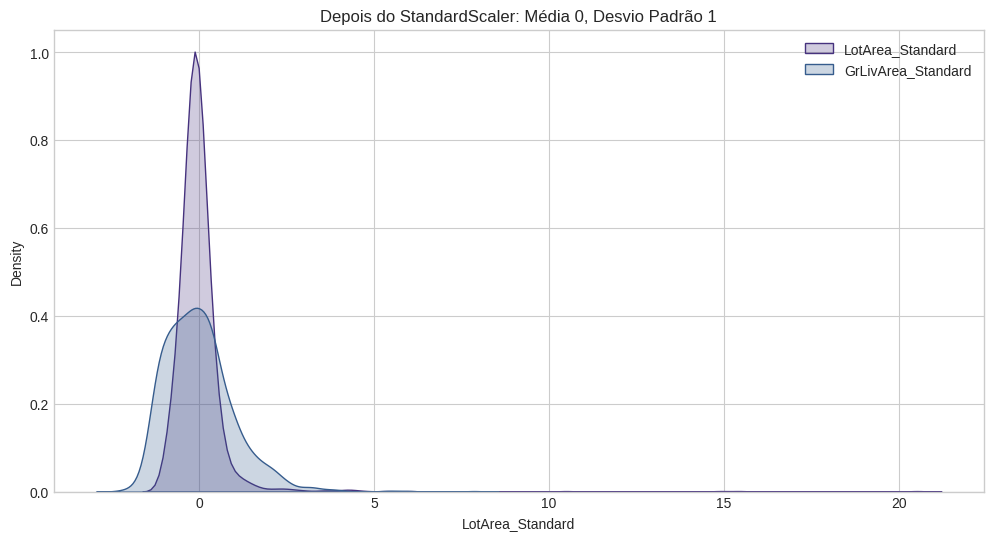

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_standard = StandardScaler()
df_scaled_standard = scaler_standard.fit_transform(df[['LotArea', 'GrLivArea']])
df_scaled_standard = pd.DataFrame(df_scaled_standard, columns=['LotArea_Standard', 'GrLivArea_Standard'])

print("\n--- Depois do StandardScaler (Estatísticas) ---")
print(df_scaled_standard.describe())

plt.figure(figsize=(12, 6))
sns.kdeplot(data=df_scaled_standard, x='LotArea_Standard', label='LotArea_Standard', fill=True)
sns.kdeplot(data=df_scaled_standard, x='GrLivArea_Standard', label='GrLivArea_Standard', fill=True)
plt.title('Depois do StandardScaler: Média 0, Desvio Padrão 1')
plt.legend()
plt.show()

### Normalização (minMaxScaler)

Reescala os dados para um intervalo fixo, geralmente [0, 1]. Esta técnica é útil para algoritmos de redes neurais. porem é sensivel a outliers

$$x_{scaled} = \frac{x - x_{min}}{x_{max} - x_{min}}$$

$x_{min}$: Valor mínimo da coluna.

$x_{max}$: Valor máximo da coluna.


--- Depois do MinMaxScaler (Estatísticas) ---
       LotArea_MinMax  GrLivArea_MinMax
count     1460.000000       1460.000000
mean         0.043080          0.222582
std          0.046653          0.098998
min          0.000000          0.000000
25%          0.029229          0.149868
50%          0.038227          0.212886
75%          0.048150          0.271807
max          1.000000          1.000000


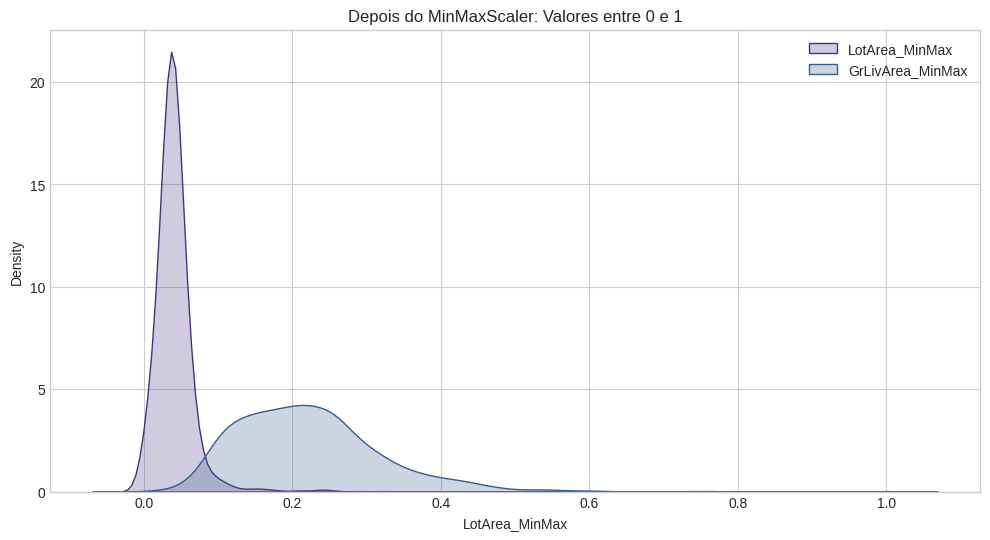

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler_minmax = MinMaxScaler()
df_scaled_minmax = scaler_minmax.fit_transform(df[['LotArea', 'GrLivArea']])
df_scaled_minmax = pd.DataFrame(df_scaled_minmax, columns=['LotArea_MinMax', 'GrLivArea_MinMax'])

print("\n--- Depois do MinMaxScaler (Estatísticas) ---")
print(df_scaled_minmax.describe())

plt.figure(figsize=(12, 6))
sns.kdeplot(data=df_scaled_minmax, x='LotArea_MinMax', label='LotArea_MinMax', fill=True)
sns.kdeplot(data=df_scaled_minmax, x='GrLivArea_MinMax', label='GrLivArea_MinMax', fill=True)
plt.title('Depois do MinMaxScaler: Valores entre 0 e 1')
plt.legend()
plt.show()

### Escala Robusta (RobustScaler)
 Reescala os dados usando estatísticas que são robustas a outliers (mediana e intervalo interquartil). É a melhor escolha quando seus dados contêm muitos valores extremos.

 $$x_{scaled} = \frac{x - Q_2(x)}{Q_3(x) - Q_1(x)}$$

 $Q_2(x)$: Mediana.

 $Q_3(x) - Q_1(x)$: Intervalo Interquartil (IQR).


--- Depois do RobustScaler (Estatísticas) ---
       LotArea_Robust  GrLivArea_Robust
count     1460.000000       1460.000000
mean         0.256504          0.079511
std          2.465728          0.811866
min         -2.020380         -1.745848
25%         -0.475543         -0.516802
50%          0.000000          0.000000
75%          0.524457          0.483198
max         50.831645          6.455002


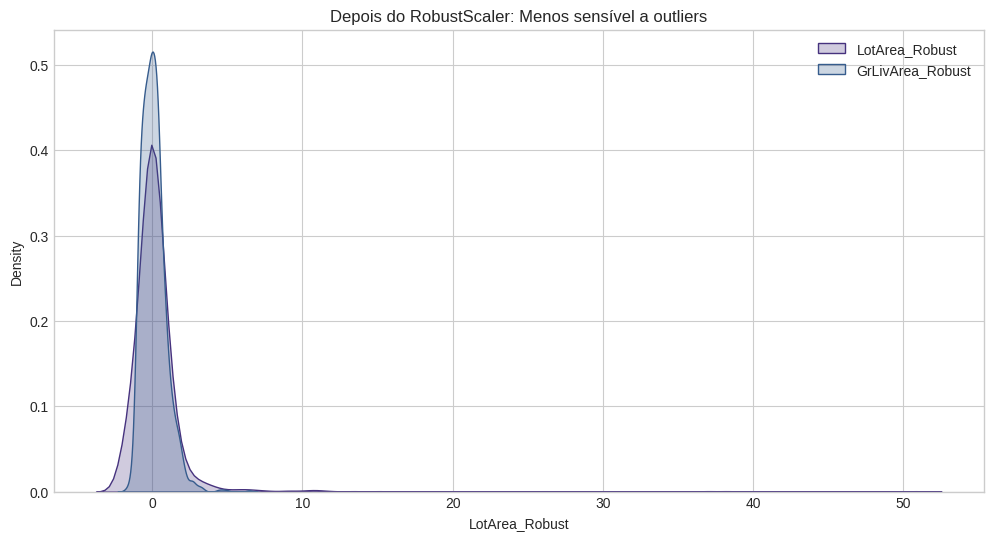

In [ ]:
from sklearn.preprocessing import RobustScaler

scaler_robust = RobustScaler()
df_scaled_robust = scaler_robust.fit_transform(df[['LotArea', 'GrLivArea']])
df_scaled_robust = pd.DataFrame(df_scaled_robust, columns=['LotArea_Robust', 'GrLivArea_Robust'])

print("\n--- Depois do RobustScaler (Estatísticas) ---")
print(df_scaled_robust.describe())

plt.figure(figsize=(12, 6))
sns.kdeplot(data=df_scaled_robust, x='LotArea_Robust', label='LotArea_Robust', fill=True)
sns.kdeplot(data=df_scaled_robust, x='GrLivArea_Robust', label='GrLivArea_Robust', fill=True)
plt.title('Depois do RobustScaler: Menos sensível a outliers')
plt.legend()
plt.show()

# Passo 5: Remoção de Multicolinearidade

Identificar e remover variáveis preditoras que são altamente correlacionadas entre si (Analise da matriz de correlação). A multicolinearidade pode tornar os coeficientes de modelos lineares instáveis e difíceis de interpretar.

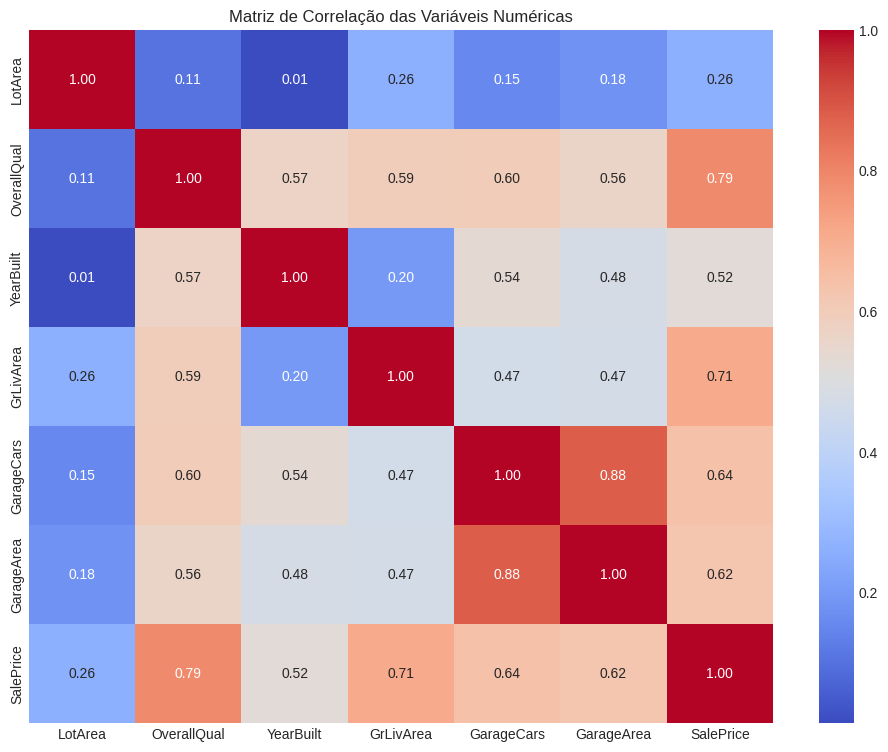

In [ ]:
# Selecionar apenas as colunas numéricas originais
df_numeric = df.select_dtypes(include=np.number)

# Calcular a matriz de correlação
corr_matrix = df_numeric.corr()

# Visualizar a matriz com um heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlação das Variáveis Numéricas')
plt.show()

In [ ]:
# Vimos que Numero de vagas na garagem esta relacionado com a area da garagem
#Ver correlação das duas variáveis com o alvo para decidir qual remover
print("\n--- Correlação com SalePrice ---")
print(corr_matrix['SalePrice'][['GarageCars', 'GarageArea']])

# Decisão: 'GarageCars' tem uma correlação ligeiramente maior com SalePrice (0.64 vs 0.62).
# Vamos remover 'GarageArea'.

df_sem_multicol = df.drop('GarageArea', axis=1)



--- Correlação com SalePrice ---
GarageCars    0.640409
GarageArea    0.623431
Name: SalePrice, dtype: float64


###Passo 6: Remoção de Variações Quase Nulas (Near-Zero Variance)
Remover features que têm pouca ou nenhuma variação, ou seja, são quase constantes. Essas variáveis não fornecem informação útil para o modelo. Resultando em modelos mais simples e rapidos de treinar, o ponto de corte recomendado é 1% a 5%


In [ ]:
print("--- Distribuição de Valores da Coluna 'Street' ---")
print(df['Street'].value_counts(normalize=True))

--- Distribuição de Valores da Coluna 'Street' ---
Street
Pave    0.99589
Grvl    0.00411
Name: proportion, dtype: float64


In [ ]:
#Mais de 99.5% das casas estão na rua "Pave" (pavimentada).
#Esta coluna é quase constante e provavelmente não ajudará o modelo a distinguir os preços das casas.
from sklearn.feature_selection import VarianceThreshold

# Aplicar One-Hot Encoding em 'Street' e outras para criar o cenário
df_para_vt = pd.get_dummies(df[['Street', 'MSZoning']])

# VarianceThreshold remove features cuja variância não atinge um certo limiar.
# Um limiar comum para dados binários (0/1) é p * (1 - p), onde p é a % da categoria mais frequente.
# Para 'Street_Pave' (99.5%), a variância é baixíssima.
# p = 0.99589
# variancia = 0.99589 * (1 - 0.99589) = 0.00409
threshold = 0.01 # Vamos definir um limiar de 1%

selector = VarianceThreshold(threshold=threshold)
selector.fit(df_para_vt)

# Colunas que foram mantidas
colunas_mantidas = df_para_vt.columns[selector.get_support()]

print(f"\nColunas originais: {df_para_vt.columns.tolist()}")
print(f"Colunas mantidas após VarianceThreshold(threshold={threshold}): {colunas_mantidas.tolist()}")

# As colunas de 'Street' ('Street_Grvl', 'Street_Pave') foram removidas.
df_sem_nzv = df.drop('Street', axis=1)


Colunas originais: ['Street_Grvl', 'Street_Pave', "MSZoning_'C (all)'", 'MSZoning_FV', 'MSZoning_RH', 'MSZoning_RL', 'MSZoning_RM']
Colunas mantidas após VarianceThreshold(threshold=0.01): ['MSZoning_FV', 'MSZoning_RH', 'MSZoning_RL', 'MSZoning_RM']


### atividade: O que eu a firmei anteriormente é verdade? De que a rua não importa no valor da casa


In [ ]:
# Comparar a média de preço por tipo de rua
print(df.groupby('Street')['SalePrice'].mean().diff())

Street
Grvl             NaN
Pave    50940.038514
Name: SalePrice, dtype: float64


<Axes: xlabel='SalePrice', ylabel='Density'>

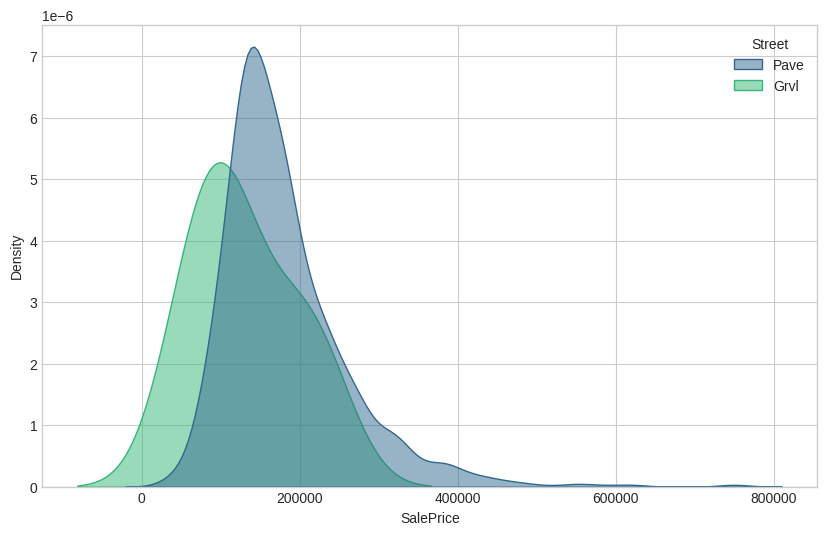

In [ ]:
sns.kdeplot(data=df, x='SalePrice', hue='Street', fill=True, common_norm=False, palette='viridis', alpha=0.5)

### Passo 7: Redução de Dimensionalidade com PCA

A Redução de Dimensionalidade busca simplificar o dataset projetando os dados em um subespaço de menor dimensão. A técnica mais utilizada é o PCA (Principal Component Analysis) ou Análise de Componentes Principais, PCA é extremamente sensível à escala dos dados portanto é obrigatório padronizar os dados antes de aplicar PCA.

In [ ]:
from sklearn.decomposition import PCA


# Usaremos o DataFrame numérico que geramos no capitulo anterior sem a variável de alta correlação que removemos
df_numeric_pca = df_sem_multicol.select_dtypes(include=np.number).drop('SalePrice', axis=1)

# Padronizar os dados
scaler_pca = StandardScaler()
df_scaled_pca = scaler_pca.fit_transform(df_numeric_pca)


print(f"features numéricas: {df_numeric_pca.columns.tolist()}")

features numéricas: ['LotArea', 'OverallQual', 'YearBuilt', 'GrLivArea', 'GarageCars']


Componente Principal contribuições [0.51011156 0.21434718 0.1395355  0.08332385 0.0526819 ]


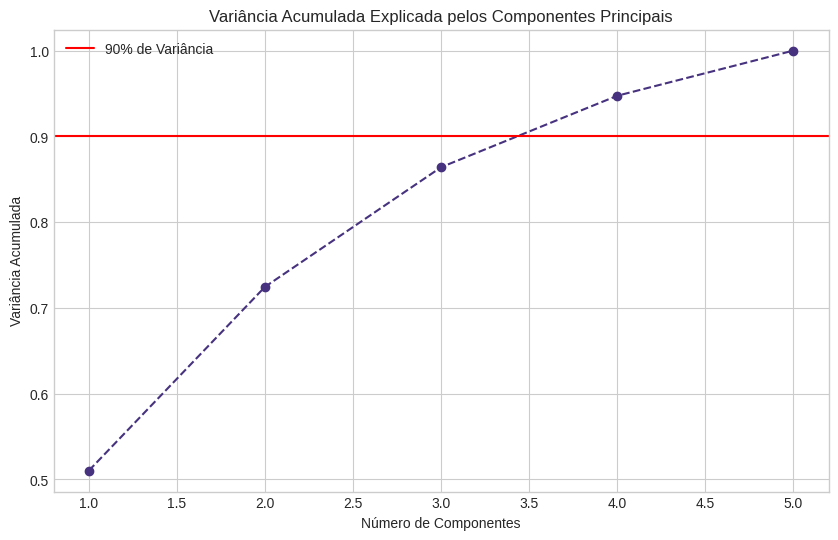


--- Contribuição de cada variável para os Componentes Principais ---


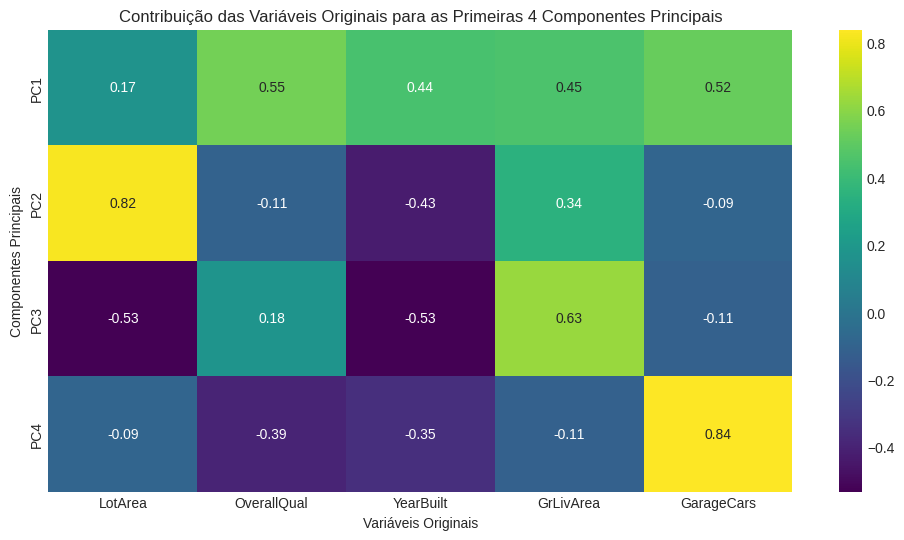

In [ ]:
# Aplicamos PCA para analisar a variância explicada
pca_analise = PCA() # declara o modelo
pca_analise.fit(df_scaled_pca) # aplicamos os modelos ao nossos dados
variancia_acumulada = np.cumsum(pca_analise.explained_variance_ratio_)

print(f'Componente Principal contribuições {pca_analise.explained_variance_ratio_}')

# Gráfico da variância acumulada
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(variancia_acumulada) + 1), variancia_acumulada, marker='o', linestyle='--')
plt.title('Variância Acumulada Explicada pelos Componentes Principais')
plt.xlabel('Número de Componentes')
plt.ylabel('Variância Acumulada')
plt.axhline(y=0.90, color='r', linestyle='-', label='90% de Variância')
plt.legend()
plt.grid(True)
plt.show()

# Adicionar a análise de contribuição das variáveis
print("\n--- Contribuição de cada variável para os Componentes Principais ---")
# A matriz de componentes principais (components_) tem a forma (n_components, n_features)
# Cada linha representa um componente principal, e cada coluna representa uma feature original
# O valor na posição (i, j) é o peso da feature j no componente principal i
component_matrix = pd.DataFrame(pca_analise.components_, columns=df_numeric_pca.columns, index=[f'PC{i+1}' for i in range(pca_analise.n_components_)])


# Visualizar a contribuição das primeiras 4 componentes graficamente
plt.figure(figsize=(12, 6))
sns.heatmap(component_matrix.head(4), annot=True, cmap='viridis', fmt=".2f")
plt.title('Contribuição das Variáveis Originais para as Primeiras 4 Componentes Principais')
plt.xlabel('Variáveis Originais')
plt.ylabel('Componentes Principais')
plt.show()

No primeiro grafico podemos identificar a contribuição de cada uma das componentes para a variabilidade ("quantidade de informação disponivel"), note que a primeira componente, a nova variável, consegui explicar 51 % da variabilidade dos dados.
O segundo grafico mostra qual foi a contribuição (pesos) de cada variavel para cada componente.

In [ ]:
#O gráfico mostra que podemos capturar 90% da variabilidade original usando apenas 4 dos 5 componentes, em vez de todas as 5 features originais.
# Aplicar PCA para de fato reduzir a dimensionalidade, retendo 90% da variância
pca_final = PCA(n_components=0.90) # calcula o menor numero de variaveis para obter no minimo 90% da retenção de variancia
df_pca_transformado = pca_final.fit_transform(df_scaled_pca)

print(f"\n--- Depois do PCA ---")
print(f"Número de componentes principais (features): {df_pca_transformado.shape[1]}")
print("\nAmostra dos dados transformados pelo PCA:")
# Generate column names based on the number of components
pca_column_names = [f'PC{i+1}' for i in range(df_pca_transformado.shape[1])]
print(pd.DataFrame(df_pca_transformado, columns=pca_column_names).head())


--- Depois do PCA ---
Número de componentes principais (features): 4

Amostra dos dados transformados pelo PCA:
        PC1       PC2       PC3       PC4
0  1.116592 -0.591378 -0.134707 -0.381254
1 -0.041982 -0.329636 -0.385140  0.297565
2  1.200430 -0.282067 -0.156710 -0.400368
3  0.547253  0.628678  1.218140  1.738803
4  2.683865  0.050733  0.176239  0.333607


Reduzimos o número de features numéricas de 15 para 7, ao mesmo tempo em que garantimos que 90% da "informação" original (variabilidade) foi mantida. As novas colunas (PC1, PC2, etc.) são combinações lineares das features originais e não são diretamente interpretáveis, mas são muito eficientes para o treinamento de modelos.

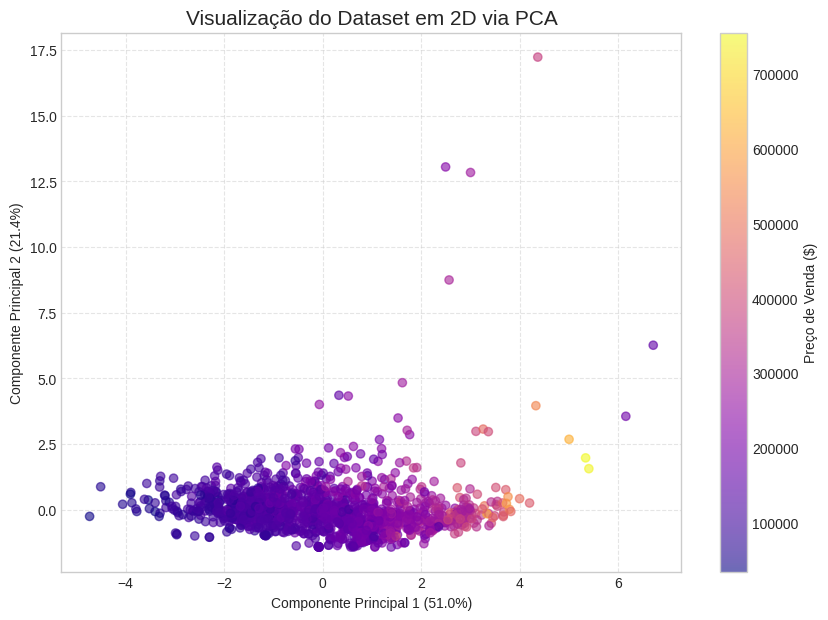

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Preparação: Selecionar apenas numéricas e tratar nulos
X = df_sem_multicol.select_dtypes(include=np.number).drop('SalePrice', axis=1)
y = df['SalePrice']

# Padronização (Indispensável para o PCA)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Aplicar PCA (reduzir todas as colunas para apenas 2)
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)

# 4. Criar DataFrame para o plot
df_pca = pd.DataFrame(data=components, columns=['PC1', 'PC2'])
df_pca['Preço'] = y.values

# 5. Gráfico de Dispersão
plt.figure(figsize=(10, 7))
scatter = plt.scatter(df_pca['PC1'], df_pca['PC2'],
            c=df_pca['Preço'], cmap='plasma', alpha=0.6)

plt.colorbar(scatter, label='Preço de Venda ($)')
plt.title('Visualização do Dataset em 2D via PCA', fontsize=15)
plt.xlabel(f'Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
import plotly.express as px

fig = px.scatter(df_pca, x='PC1', y='PC2', color='Preço',
                 hover_data=[df.index], title='Detecção Visual de Outliers (Passe o mouse)')

fig.show()

Note que temos diversos pontos  que podemos identificar como outliers, essa é uma característica positiva da PCA, ao reprojetar em um novo espaço amostral os dados, geralmente este é mais alongado em torno das primeiras componentes, assim destaca se outliers que antes eram imperceptíveis.

### Atividade: identificar os outliers utilizando as 2 primeiras componentes (outlier dos graficos anteriores)

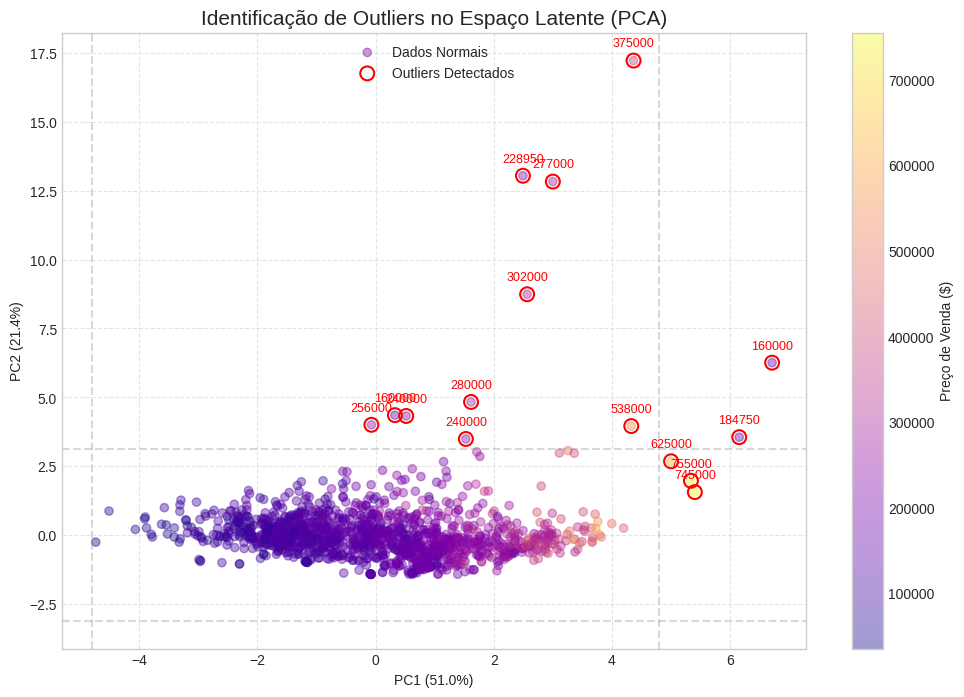

In [ ]:
# Defini o critério de outlier (ex: mais de 3 desvios padrões)
threshold = 3
outliers_mask = (np.abs(df_pca['PC1']) > threshold * df_pca['PC1'].std()) | \ # ou e \ indica nova linha
                (np.abs(df_pca['PC2']) > threshold * df_pca['PC2'].std())

outliers = df_pca[outliers_mask]

# Gráfico de Dispersão
plt.figure(figsize=(12, 8))

# Plota todos os pontos
scatter = plt.scatter(df_pca['PC1'], df_pca['PC2'],
            c=df_pca['Preço'], cmap='plasma', alpha=0.4, label='Dados Normais')

# Destaca os Outliers com uma borda ou marcador diferente
plt.scatter(outliers['PC1'], outliers['PC2'],
            facecolors='none', edgecolors='red', s=100, linewidths=1.5, label='Outliers Detectados')

# Anotar o índice dos outliers mais extremos para conferência
for i in outliers.index:
    plt.annotate(df_pca["Preço"][i], (df_pca.loc[i, 'PC1'], df_pca.loc[i, 'PC2']),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=9, color='red')

plt.colorbar(scatter, label='Preço de Venda ($)')
plt.title('Identificação de Outliers no Espaço Latente (PCA)', fontsize=15)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')

# Adicionar linhas de threshold (3 sigma)
plt.axvline(threshold * df_pca['PC1'].std(), color='gray', linestyle='--', alpha=0.3)
plt.axvline(-threshold * df_pca['PC1'].std(), color='gray', linestyle='--', alpha=0.3)

plt.axhline(threshold * df_pca['PC2'].std(), color='gray', linestyle='--', alpha=0.3)
plt.axhline(-threshold * df_pca['PC2'].std(), color='gray', linestyle='--', alpha=0.3)

plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Aplicando o isolation forest nas duas componentes

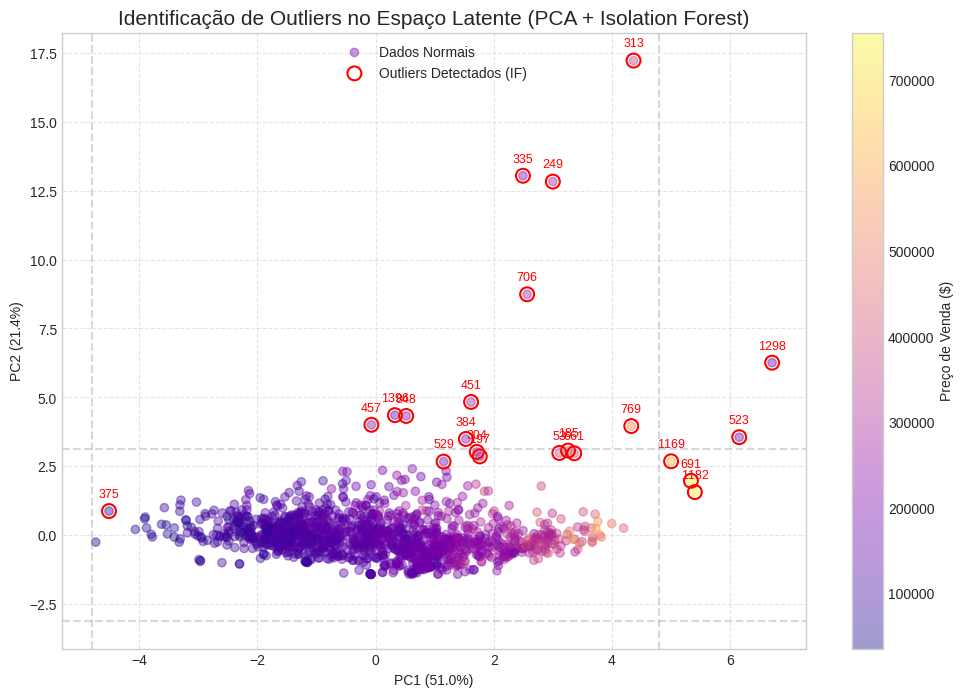

In [ ]:
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

# 1. Definir o modelo
iso_forest = IsolationForest(contamination=0.015, random_state=42)

#  Treinar nas duas principais componentes
# Assumindo que df_pca já contém 'PC1' e 'PC2'
outliers_labels = iso_forest.fit_predict(df_pca[['PC1', 'PC2']])

# Filtrar os outliers para o destaque (Isolation Forest retorna -1 para outliers)
outliers = df_pca[outliers_labels == -1]

# Gráfico de Dispersão
plt.figure(figsize=(12, 8))

# Plotar todos os pontos coloridos pelo Preço
scatter = plt.scatter(df_pca['PC1'], df_pca['PC2'],
            c=df_pca['Preço'], cmap='plasma', alpha=0.4, label='Dados Normais')

# Destacar os Outliers detectados pelo Isolation Forest
plt.scatter(outliers['PC1'], outliers['PC2'],
            facecolors='none', edgecolors='red', s=100, linewidths=1.5, label='Outliers Detectados (IF)')

# Anotar o índice dos outliers para auditoria em sala de aula
for i in outliers.index:
    plt.annotate(i, (df_pca.loc[i, 'PC1'], df_pca.loc[i, 'PC2']),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=9, color='red')

plt.colorbar(scatter, label='Preço de Venda ($)')
plt.title('Identificação de Outliers no Espaço Latente (PCA + Isolation Forest)', fontsize=15)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')

# Adicionar linhas de threshold (Referência estatística de 3 sigmas)
threshold = 3
plt.axvline(threshold * df_pca['PC1'].std(), color='gray', linestyle='--', alpha=0.3)
plt.axvline(-threshold * df_pca['PC1'].std(), color='gray', linestyle='--', alpha=0.3)
plt.axhline(threshold * df_pca['PC2'].std(), color='gray', linestyle='--', alpha=0.3)
plt.axhline(-threshold * df_pca['PC2'].std(), color='gray', linestyle='--', alpha=0.3)

plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Engenharia de atributos

Os pontos vistos até agora foram os passos mais técnicos, regidos, entretanto o diferencial de bom cientista de dados esta na sua capacidade de agregar informação ao se conjunto de dados, com a adição/criação de novas variáveis mais qualificadas.

O ponto chave neste quesito é ter um bom conhecimento de background sobre a temática que esta sendo abordada (seja mercado imobiliário, saúde ou agronegócio) que vai permitir o reconhecimento de padrões que facilitam o trabalho dos algoritmos de Aprendizado de Máquina.

 Vocês verão nos modulos mais a frente que existe um 'duelo' (trade-off) entre variância e viés. Buscamos modelos que sejam complexos o suficiente para aprender o padrão, mas simples o suficiente para generalizar bem para novos dados. É aqui que a engenharia de recursos faz seu papel:, por exemplo. Em vez de forçar uma Árvore de Decisão a gastar vários nós (profundidade) para entender a relação entre peso e altura, podemos entregar o IMC pronto, com as relações básicas já consolidadas em novas colunas, o modelo fica livre para focar em correlações mais sutis e complexas na qual não conseguimos observar.






In [ ]:
# vamos selecionar um conjunto de dados e trabalhar em cima dele.
features_selecionadas = [
    'LotArea', 'OverallQual', 'YearBuilt', 'GrLivArea', 'GarageCars', 'GarageArea',
    'MSZoning', 'Neighborhood', 'BldgType', 'GarageType', 'FireplaceQu', 'Street',
    'YrSold','YearRemodAdd'
]
target = 'SalePrice'

# Criando um DataFrame de trabalho
df = df_original[features_selecionadas + [target]].copy()

Variaveis temporais podem ser manipuladas com facilidade e são sempre uteis.

In [ ]:

# Usamos 'YrSold' (Ano da Venda) para ter a idade exata na transação
df['idade'] = df['YrSold'] - df['YearBuilt']

#Anos desde a última reforma('YearRemodAdd'), esse tipo se aplica a outros casos como: dias desde a ultima compra, dias sem comparesser
df['desda_reforma'] = df['YrSold'] - df['YearRemodAdd']

# Criar uma variável binária indicando se a casa foi reformada
# A casa foi reformada se YearRemodAdd for diferente de YearBuilt
df['FoiReformada'] = (df['YearRemodAdd'] != df['YearBuilt']).astype(int)

print(df[['YearBuilt', 'YearRemodAdd', 'YrSold', 'idade', 'desda_reforma', 'FoiReformada']].head())



   YearBuilt  YearRemodAdd  YrSold  idade  desda_reforma  FoiReformada
0       2003          2003    2008      5              5             0
1       1976          1976    2007     31             31             0
2       2001          2002    2008      7              6             1
3       1915          1970    2006     91             36             1
4       2000          2000    2008      8              8             0


Aproveitando que estamos falando da questão de tempo, quando estamos trabalhando com series temporais, temos alguns aspectos que podem ser importantes:


*   Componentes do tempo: processo basico, por exemplo trabalhar com uma coluna com os dias da semana, ou distinção entre dias da semana do final de semana, trabalhar com o mes, ou trimestre, saber se é um feriado. são informações pertinentes que muitas vezes passa despercebido.
```
df['mes'] = df['Data'].dt.month
df['dia_da_semana'] = df['Data'].dt.dayofweek
df['eh_fim_de_semana'] = df['dia_da_semana'].isin([5, 6]).astype(int)
```
*   **Lags:** podemos deslocar os dados para tras para captar auto correlação (vimos no material de [serie temporal](https://colab.research.google.com/drive/1JrS2YaJb6rHbbwZ-7baO2y87VC-DjLVG)), por exemplo qual era o preço da casa a 2 meses atras?  (não temos essa informação, mas seria interessante acrescentar uma nova coluna, valor no ultimo mês, dois meses...1 ano, o modelo pode captar alguma tendencia de crescimento ou queda.)

```
df['lag_1'] = df['SalePrice'].shift(1)  # Valor do passo anterior
```

*   **Rolling Windows (Janelas Móveis)**: podemos suavizar ruídos trabalhando com medias do período, se o interesse não for o dado na frequência apresentada, trabalhar com valores mensais ao invés de diário por exemplo., detalhe: não se atenha só a valores médios, desvios padrões e acumulados também são validos. Atenção ao dataLeak (veremos as seguir)
```
df['media_movel_7d'] = df['SalePrice'].rolling(window=7).mean() # Média da última semana
```
* Diferenciação: Muitas vezes, o valor absoluto não importa tanto quanto a mudança. Saber que o preço é 200k é menos informativo do que saber que ele subiu 5k desde ontem. A diferenciação ajuda a tornar a série Estacionária (média e variância constantes), o que é um requisito para muitos modelos estatísticos.

```
df['variacao_diaria'] = df['SalePrice'].diff() # Diferença entre hoje e ontem
```
Agora seguimos com mais alguns aspectos de engenharia de recursos no nosso dataset

In [ ]:
# Multiplicando a qualidade geral pela área, tamanho não importa, deve ter qualidade
df['QualityArea'] = df['OverallQual'] * df['GrLivArea']

print(df[['OverallQual', 'GrLivArea', 'QualityArea']].head())

   OverallQual  GrLivArea  QualityArea
0            7       1710        11970
1            6       1262         7572
2            7       1786        12502
3            7       1717        12019
4            8       2198        17584


In [ ]:
#Razão é uma das forma mais simples de se obter novas variaveis
#Evitar divisão por zero para casas sem garagem
df['GarageAreaPerCar'] = df['GarageArea'] / df['GarageCars']
df['GarageAreaPerCar'].fillna(0, inplace=True) # Preenche com 0 se não houver carros/garagem

print("\n--- Área da Garagem por Carro ---")
print(df[['GarageCars', 'GarageArea', 'GarageAreaPerCar']].head())


--- Área da Garagem por Carro ---
   GarageCars  GarageArea  GarageAreaPerCar
0           2         548        274.000000
1           2         460        230.000000
2           2         608        304.000000
3           3         642        214.000000
4           3         836        278.666667


Podemos gerar essas interações de forma automática pra dados numéricos por meio `da PolynomialFeatures`

Colunas Originais vs Novas Features:
   GrLivArea  OverallQual  YearBuilt  GrLivArea OverallQual  \
0     1710.0          7.0     2003.0                11970.0   
1     1262.0          6.0     1976.0                 7572.0   
2     1786.0          7.0     2001.0                12502.0   
3     1717.0          7.0     1915.0                12019.0   
4     2198.0          8.0     2000.0                17584.0   

   GrLivArea YearBuilt  OverallQual YearBuilt  
0            3425130.0                14021.0  
1            2493712.0                11856.0  
2            3573786.0                14007.0  
3            3288055.0                13405.0  
4            4396000.0                16000.0  


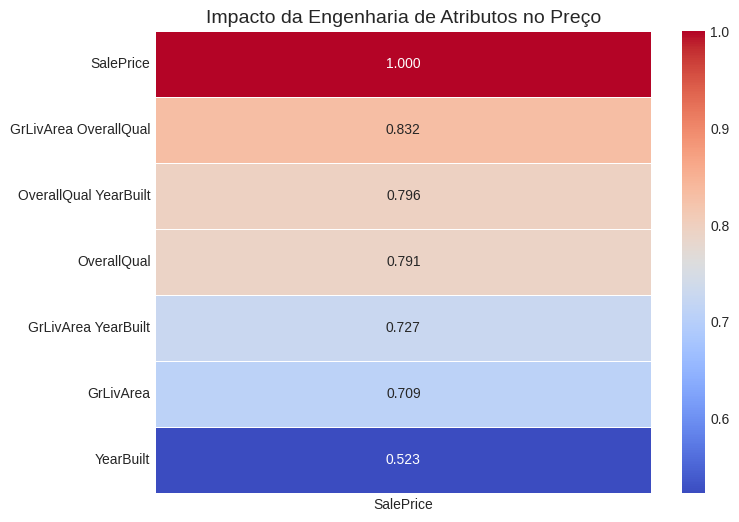

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

#  Selecionando as variáveis de interesse
X_subset = df[['GrLivArea', 'OverallQual','YearBuilt']]

# Configurando o PolynomialFeatures
# degree=2: cria quadrados e interações
# interaction_only=True: se quiser APENAS o cruzamento (x1 * x2), sem os quadrados
poly = PolynomialFeatures(degree=2, include_bias=False,interaction_only=True)

# Ajustando e transformando
X_poly = poly.fit_transform(X_subset)

# Criando um DataFrame para visualizar o resultado com os nomes das colunas
niveis = poly.get_feature_names_out(['GrLivArea', 'OverallQual','YearBuilt'])
df_poly = pd.DataFrame(X_poly, columns=niveis)

print("Colunas Originais vs Novas Features:")
print(df_poly.head())

#  Adicionamos o Alvo (SalePrice) de volta para calcular a correlação
df_poly['SalePrice'] = df['SalePrice'].values


correlacao = df_poly.corr()[['SalePrice']].sort_values(by='SalePrice', ascending=False)

# Plotagem do Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlacao, annot=True, cmap='coolwarm', fmt=".3f", linewidths=0.5)

plt.title('Impacto da Engenharia de Atributos no Preço', fontsize=14)
plt.show()





Mais algumas variaveis que podemos gerar

In [ ]:
# A casa tem garagem? (Qualquer valor de área > 0)
df['HasGarage'] = (df['GarageArea'] > 0).astype(int)

# A casa tem lareira? (Veremos como tratar o nulo de 'FireplaceQu' a seguir,
# mas a lógica seria baseada se a qualidade da lareira é conhecida ou não)
df['HasFireplace'] = df['FireplaceQu'].notna().astype(int)

print("\n--- Features Binárias (Presença de Garagem/Lareira) ---")
print(df[['GarageArea', 'HasGarage', 'FireplaceQu', 'HasFireplace']].head())


--- Features Binárias (Presença de Garagem/Lareira) ---
   GarageArea  HasGarage FireplaceQu  HasFireplace
0         548          1         NaN             0
1         460          1          TA             1
2         608          1          TA             1
3         642          1          Gd             1
4         836          1          TA             1


In [ ]:
# Substituindo NaN por uma categoria 'None'
df['FireplaceQu'].fillna('None', inplace=True)
df['GarageType'].fillna('None', inplace=True)

print("\n--- Tratamento de Nulos Categóricos ---")
print("Valores únicos em FireplaceQu:", df['FireplaceQu'].unique())
print("Valores únicos em GarageType:", df['GarageType'].unique())


--- Tratamento de Nulos Categóricos ---
Valores únicos em FireplaceQu: ['None' 'TA' 'Gd' 'Fa' 'Ex' 'Po']
Valores únicos em GarageType: ['Attchd' 'Detchd' 'BuiltIn' 'CarPort' 'None' 'Basment' '2Types']


In [ ]:
# Criando o mapa de qualidade
fireplace_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
df['FireplaceQu_Encoded'] = df['FireplaceQu'].map(fireplace_map)

print("\n--- Mapeamento Ordinal de FireplaceQu ---")
print(df[['FireplaceQu', 'FireplaceQu_Encoded']].head())


--- Mapeamento Ordinal de FireplaceQu ---
  FireplaceQu  FireplaceQu_Encoded
0        None                    0
1          TA                    3
2          TA                    3
3          Gd                    4
4          TA                    3


Esses cruzamentos podem se dar de outras maneiras, como categóricos, exemplo o bairro luxuoso com uma casa em baixa qualidade, mas atentem que isso pode gerar muitas novas classes e algumas de baixa representatividade.

In [ ]:
# Criando uma interação entre Bairro e Condição da Casa para cria uma nova classe
df['Bairro_Condicao'] = df['Neighborhood'] + "_" + df['OverallQual'].astype(str)

print(df[['Neighborhood','OverallQual', 'Bairro_Condicao']].head())

total_classes_unicas = df['Bairro_Condicao'].nunique()
print(f"Total de classes únicas: {total_classes_unicas}")


contagem_classes = df['Bairro_Condicao'].value_counts()

print(contagem_classes) # poderiamos criar alguns bins para o OverallQuall (baixa_media_alta)

  Neighborhood  OverallQual Bairro_Condicao
0      CollgCr            7       CollgCr_7
1      Veenker            6       Veenker_6
2      CollgCr            7       CollgCr_7
3      Crawfor            7       Crawfor_7
4      NoRidge            8       NoRidge_8
Total de classes únicas: 114
Bairro_Condicao
NAmes_5       113
NAmes_6        74
CollgCr_7      71
Sawyer_5       54
OldTown_5      47
             ... 
SWISU_2         1
Veenker_7       1
NoRidge_9       1
Gilbert_9       1
Somerst_10      1
Name: count, Length: 114, dtype: int64


## PIPELINE

Vimos até então os principais pontos de atenção no pré-processamento de dados.

Agora vamos ver como podemos desenvolver os conceitos anteriores dentro de uma *Pipeline* que permitira ter um fluxo de trabalho coerente evitando uns dos principais erro cometidos por analistas iniciantes: O Vazamento de dados (data leakage)

* Data leakage: Ocorre quando o seu modelo, durante o treinamento, tem acesso (direto ou indireto) a informações sobre o grupo de teste. Por exemplo: treinar o modelo usando uma media movel que observou os dados do grupo de teste ao ser elaborada, ao ser treinado o modelo tera acesso indireto na media aos valores que no mundo real ele nunca teria acesso, porem no treino foi possivel devido a media movel.



In [ ]:
# vamos demostrar o efeito em uma dataset sobre cancer de mama

import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np

# Carregar o dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

# Para este exemplo, vamos apenas ver as 5 primeiras colunas

print(X.head().iloc[:, :5])
print("\n-Alvo -")
print(y.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness
0        17.99         10.38          122.80     1001.0          0.11840
1        20.57         17.77          132.90     1326.0          0.08474
2        19.69         21.25          130.00     1203.0          0.10960
3        11.42         20.38           77.58      386.1          0.14250
4        20.29         14.34          135.10     1297.0          0.10030

-Alvo -
0    0
1    0
2    0
3    0
4    0
dtype: int64


In [ ]:
### MODO ERRADO

# Aplica o Scaler no dataset INTEIRO
scaler_errado = StandardScaler()
X_scaled_errado = scaler_errado.fit_transform(X) # <-- LEAKAGE, O scaler "viu" o X_test.

# Dividi os dados DEPOIS de escalar
# Usamos random_state para garantir que a divisão seja a mesma do exemplo correto
X_train_err, X_test_err, y_train_err, y_test_err = train_test_split(
    X_scaled_errado, y, test_size=0.5, random_state=2025
)

# Treina e Avalia
model_errado = LogisticRegression()
model_errado.fit(X_train_err, y_train_err)
score_errado = model_errado.score(X_test_err, y_test_err)

print(f"Acurácia (Errada): {score_errado:.4f}")


Acurácia (Errada): 0.9719


In [ ]:
### MODDO CORRETO

# Dividi os dados ANTES de qualquer pré-processamento
# Usamos o MESMO random_state para uma comparação justa
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=2025
)

#Criar o Scaler
scaler_correto = StandardScaler()

#Aprender (fit) a média/std APENAS no TREINO
X_train_scaled = scaler_correto.fit_transform(X_train)

#APLICAR (transform) a transformação aprendida no TESTE
X_test_scaled = scaler_correto.transform(X_test) # <-- Apenas .transform()

#Treinar e Avaliar
model_correto = LogisticRegression()
model_correto.fit(X_train_scaled, y_train)
score_correto = model_correto.score(X_test_scaled, y_test)

print(f"Acurácia (Correta): {score_correto:.4f}")


Acurácia (Correta): 0.9684


In [ ]:


# Média da feature 'mean radius' (índice 0) aprendida pelo scaler ERRADO (com dados totais)
media_errada = scaler_errado.mean_[0]

# Média da feature 'mean radius' (índice 0) aprendida pelo scaler CORRETO (só com treino)
media_correta = scaler_correto.mean_[0]

print(f"Média aprendida errada: {media_errada:.10f}")
print(f"Média aprendida correta : {media_correta:.10f}")
print(f"Diferença: {abs(media_errada - media_correta):.10f}")

Média aprendida errada: 14.1272917399
Média aprendida correta : 14.0471654930
Diferença: 0.0801262469


Podemos utilizar um recurso, `Pipeline` do *scikitlearn*, o padrão ouro para evitar o dataleak bem como auxilar no processo de organização do pre-processamento e processamento. Encapsulando todo pre-procemento em um unico objeto.

In [ ]:
### USANDO O PIPE

from sklearn.pipeline import Pipeline

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=2025
)

# O pipeline é uma "linha de montagem"
# Passo 1: 'scaler' (aplica StandardScaler)
# Passo 2: 'modelo' (aplica LogisticRegression)
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', LogisticRegression())
])

# Treina o Pipeline
# Trate o 'pipe' como se fosse um modelo normal (como o LogisticRegression)
# VOCÊ PASSA OS DADOS DE TREINO BRUTOS (X_train)
pipe.fit(X_train, y_train)

# O que aconteceu DENTRO do pipe.fit():
# 1. O pipeline chamou scaler.fit_transform(X_train)
# 2. O pipeline pegou o resultado disso e chamou modelo.fit(resultado_do_scaler, y_train)
# TUDO AUTOMATICAMENTE E SEM VAZAMENTO.

# Avalia o Pipeline
# VOCÊ PASSA OS DADOS DE TESTE BRUTOS (X_test)
score_pipeline = pipe.score(X_test, y_test)

# O que aconteceu DENTRO do pipe.score():
# 1. O pipeline chamou scaler.transform(X_test)
# 2. O pipeline pegou o resultado disso e chamou modelo.score(resultado_do_scaler, y_test)


print(f"Acurácia (Com Pipeline): {score_pipeline:.4f}")


Acurácia (Com Pipeline): 0.9684


In [ ]:
pipe

Pipeline(steps=[('scaler', StandardScaler()), ('modelo', LogisticRegression())])

Podemos desenvolver todo o processo dos valores das casas (datasete house_price) dentro do Pipeline

## Passo 1


*   Primeira etapa é carregar os pacotes que iremos utilizar, bem como os dados previamente analisados via AED. Lembrando que neste ponto ja temos listados algumas etapas de pre-processamento que devem ser cumpridas.
*   Por fim ter definido o básico, qual é nossa variável alvo e quais serão nossas features.



In [ ]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression # Usando um modelo de regressão como exemplo
# Carregamento e Preparação dos Dados
from sklearn.datasets import fetch_openml
house_prices = fetch_openml(name="house_prices", as_frame=True)
df_original = house_prices.frame

# Selecionar features e o alvo
features_selecionadas = [
    'LotArea', 'OverallQual', 'YearBuilt', 'GrLivArea', 'GarageCars', 'GarageArea',
    'MSZoning', 'Neighborhood', 'BldgType', 'GarageType', 'FireplaceQu', 'Street'
]
target = 'SalePrice'
df = df_original[features_selecionadas + [target]].copy() # ter um dataset completo

# >>>>>>>> PASSO 1:  Separar features (X) e alvo (y)
X = df.drop(target, axis=1)
y = df[target]


## Passo 2

* Vimos que colunas categoricas  e numericas sofrem diferentes tratamentos, então é importante definirmos as colunas pelo tipo de tratamento. Não por tipo de variavel (similar muitas vezes, mas nem sempre)

In [ ]:
# >>>>>>>> PASSO 2: Identificação das Colunas por Tipo de Tratamento

# Features NUMERICAS que precisam de scaling e possivelmente imputação/transformação
# GarageCars e OverallQual são ordinais, mas podem ser tratadas como numéricas
numeric_features = ['LotArea', 'OverallQual', 'YearBuilt', 'GrLivArea', 'GarageCars', 'GarageArea']

# Feature CATEGORICAS ORDINAIS
# Note que o valor 'None' para ausência será tratado pelo imputer
ordinal_feature = ['FireplaceQu']
ordem_lareira = ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']

# Features CATEGORICAS NOMINAIS para One-Hot Encoding
categorical_features = ['MSZoning', 'Neighborhood', 'BldgType', 'GarageType', 'Street']

# Features NUMERICAS com assimetria a ser corrigida, mesmo estando nas numericas
skewed_features = ['LotArea', 'GrLivArea']



## Passo 3

* Dividir o dataset em Treino e Teste (existem outras maneiras de se dividir)

In [ ]:
# >>>>>>>>> PASSO 3. Divisão em Treino e Teste
# A divisão é feita ANTES de qualquer `fit` ou `transform`.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=25)

## Passo 4

* Definir o Pipeline com os passos de preprocessaemnto que iremos adotar.
* exite uma gama enorme de funções prontas de pré-processamento para mais detalhes consultem a documentação do [scikitlearn](https://scikit-learn.org/stable/data_transforms.html)

In [ ]:
# PASSO 4: Definição dos Pipelines de Pré-processamento

# Pipeline para features com assimetria
# 1. Imputa a mediana (caso haja nulos)
# 2. Aplica a transformação Yeo-Johnson
# 3. Aplica o escalonamento padrão
skewed_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('power', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

# Pipeline para as demais features numéricas
# 1. Imputa a mediana
# 2. Aplica o escalonamento padrão
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline para a feature ordinal
# 1. Imputa a constante 'None' para valores ausentes
# 2. Aplica o OrdinalEncoder com a ordem especificada
ordem_lareira = ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'] # None, Poor, Fair, Typical, Good, Excellent

ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('ordinal', OrdinalEncoder(categories=[ordem_lareira]))
])

# Pipeline para features categóricas nominais
# 1. Imputa o valor mais frequente (uma estratégia segura para estas colunas)
# 2. Aplica o OneHotEncoder
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) # Ignora categorias novas no teste e retorna array denso
])


# >>>>>> Criação do ColumnTransformer para Unir os Pipelines

# O ColumnTransformer aplica os transformadores corretos às colunas corretas.
# Note que separamos as numéricas com e sem correção de assimetria.
preprocessor = ColumnTransformer(
    transformers=[
        ('skew', skewed_transformer, skewed_features),
        ('num', numeric_transformer, list(set(numeric_features) - set(skewed_features))), # Numéricas não assimétricas
        ('ord', ordinal_transformer, ordinal_feature),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# >>>>>  Criação do Pipeline Final com o Modelo
# O fluxo é: 1) Pré-processar os dados com o ColumnTransformer, 2) Treinar o modelo.
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

## Passo 5

* Executar o treinamento do modelo por meio do `fit`, lembrando que o `pipeline` ja orquestrara todo o processo de maneira organica e limpa.

* Por fim determinar o score dos nossos dados.

In [ ]:
#>>>>>>> Passo 5. Treinamento e Avaliação

# Ao chamar .fit(), o pipeline executa o .fit_transform() do pré-processador APENAS em X_train.
# Os parâmetros (medianas, lambdas, médias, desvios-padrão, categorias) são aprendidos SOMENTE com os dados de treino.
model_pipeline.fit(X_train, y_train)

# Ao chamar .score() ou .predict(), o pipeline aplica APENAS o .transform() em X_test,
# usando os parâmetros já aprendidos, evitando assim o vazamento de dados.
score = model_pipeline.score(X_test, y_test)


print(f"Score R² do modelo no conjunto de teste: {score:.4f}")

# Exemplo de predição em um novo dado
# O pipeline cuida de todo o pré-processamento automaticamente
#new_data = X_test.head(1)
prediction = model_pipeline.predict(X_test)
print(f"\\nExemplo de Predição para o primeiro dado do teste: ${prediction[2]:,.2f}, valor real:$ {y_test.iloc[2]:,.2f}")

Score R² do modelo no conjunto de teste: 0.7596
\nExemplo de Predição para o primeiro dado do teste: $149,738.54, valor real:$ 185,750.00


In [ ]:
model_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('skew',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('power',
                                                                   PowerTransformer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['LotArea', 'GrLivArea']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['OverallQu...
                                                                                 strategy='constant')),
                                                                  ('ordinal',
                                                                   OrdinalEncoder(categories=[['None',
                                                                                               'Po',
                                                                                               'Fa',
                                                                                               'TA',
                                                                                               'Gd',
                                                                                               'Ex']]))]),
                                                  ['FireplaceQu']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['MSZoning', 'Neighborhood',
                                                   'BldgType', 'GarageType',
                                                   'Street'])])),
                ('regressor', LinearRegression())])

Esta foi um processo básico, sem o emprego da criação e transformações mais rebuscadas sobre os dados, sem criterios de quantidade de features que estamos entrando para modelar. Agora vamos desenvolver melhor esse processo.

In [ ]:
# numero de colunas antes e depois do pipeline

print(f'antes do pipeline {X_train.shape[1]} colunas')
print(f'depois do pipeline {model_pipeline.named_steps['preprocessor'].transform(X_train).shape[1]} colunas')

antes do pipelineÇ 12 colunas
antes do pipelineÇ 50 colunas


Uma forma de diminuir a cardinalidade dos dados é por meio da PCA, para isso sacrificaremos um pouco da nossa variabilidade dos dados e sua interpretabilidade.

In [ ]:
from sklearn.decomposition import PCA

# Criação do Pipeline Final com PCA
# O fluxo agora é:
# 1) ColumnTransformer (Limpa e Transforma colunas heterogêneas)
# 2) PCA (Reduz a dimensionalidade unindo a variância das colunas)
# 3) LinearRegression (Treina nos componentes principais)

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('pca', PCA(n_components=0.95)), # Reduz para n componentes principais ou n% de variabilidade
    ('regressor', LinearRegression())
])

# Treinamento
model_pipeline.fit(X_train, y_train)

score = model_pipeline.score(X_test, y_test)


print(f"Score R² do modelo no conjunto de teste: {score:.4f}")

# Verificando as colunas
n_colunas_antes_pca = model_pipeline.named_steps['preprocessor'].transform(X_train).shape[1]
n_colunas_depois_pca = model_pipeline.named_steps['pca'].n_components_

print(f"Colunas geradas pelo preprocessor: {n_colunas_antes_pca}")
print(f"Colunas entregues ao modelo após PCA: {n_colunas_depois_pca}")

Score R² do modelo no conjunto de teste: 0.7495
Colunas geradas pelo preprocessor: 50
Colunas entregues ao modelo após PCA: 17


vamos trabalhar agora com outra forma de codificação, `targetEncoder`.

In [ ]:
from sklearn.preprocessing import TargetEncoder
# Pipeline para features categóricas nominais
# 1. Imputa o valor mais frequente
# 2. Aplica o TargetEncoder (Não cria colunas extras)
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target_enc', TargetEncoder(target_type='continuous')) # 'continuous' pois é regressão (preço)
])

# PASSO 5: O ColumnTransformer permanece o mesmo
preprocessor = ColumnTransformer(
    transformers=[
        ('skew', skewed_transformer, skewed_features),
        ('num', numeric_transformer, list(set(numeric_features) - set(skewed_features))),
        ('ord', ordinal_transformer, ordinal_feature),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# redefinimos o Pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])


# Treinamento
model_pipeline.fit(X_train, y_train)

score = model_pipeline.score(X_test, y_test)


print(f"Score R² do modelo no conjunto de teste: {score:.4f}")

# Verificação da Dimensionalidade
print(f'antes do pipelineÇ {X_train.shape[1]} colunas')
n_colunas_final = model_pipeline.named_steps['preprocessor'].n_features_in_
print(f"Total de colunas entrando no modelo: {n_colunas_final}")

Score R² do modelo no conjunto de teste: 0.7631
antes do pipelineÇ 12 colunas
Total de colunas entrando no modelo: 12


In [ ]:
model_pipeline.score(X_train, y_train) # para ver se não estamos com overfit

0.7946989791488726


Vamos fazer algumas transformações nas variáveis para ver como o modelo vai responder. Primeiro vamos fazer de forma automática com `polynomialFeatures`, isso va impactar positivamente para o modelo linear reconhecer padrões não lineares.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# PASSO 6: Pipeline Final com Polinômios
# 1. preprocessor: Limpa e codifica (incluindo o TargetEncoder)
# 2. poly: Cria interações (ex: Area * Qualidade) e termos quadráticos (Area²)
# 3. regressor: Treina o modelo linear nos dados expandidos
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)), # Grau 2 é o padrão que recomendo
    ('regressor', LinearRegression())
])

# Treinamento
model_pipeline.fit(X_train, y_train)

# Avaliação de Performance
score_train = model_pipeline.score(X_train, y_train)
score_test = model_pipeline.score(X_test, y_test)

print(f"R² no Treino (Com Polinômios): {score_train:.4f}")
print(f"R² no Teste (Com Polinômios):  {score_test:.4f}")

R² no Treino (Com Polinômios): 0.8823
R² no Teste (Com Polinômios):  0.8503


In [ ]:
# Verificação da Dimensionalidade
print(f'antes do pipelineÇ {X_train.shape[1]} colunas')
n_colunas_final = model_pipeline.named_steps['regressor'].n_features_in_
print(f"Total de colunas entrando no modelo: {n_colunas_final}")

antes do pipelineÇ 12 colunas
Total de colunas entrando no modelo: 90


Temos 90 variáveis de entrada, ok, o dado pequeno e não temos problema em processar esse volume, mas vamos assumir que é necessário trabalhar com no máximo 20 colunas e obter valor de r² superiores a 0.8 de usando um modelo linear:

Vamos remover as relações quadradicas obtidas pelo `PolynomiualFeatures`

In [ ]:

# PASSO 6: Pipeline com Polinômios
# 1. preprocessor: Limpa e codifica (incluindo o TargetEncoder)
# 2. poly: Cria interações (ex: Area * Qualidade)
# 3. regressor: Treina o modelo linear nos dados expandidos só pelas interações
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False,interaction_only=True)), # Grau 2 é o padrão que recomendo
    ('regressor', LinearRegression())
])

# Treinamento
model_pipeline.fit(X_train, y_train)

# Avaliação de Performance
score_train = model_pipeline.score(X_train, y_train)
score_test = model_pipeline.score(X_test, y_test)

print(f"R² no Treino (Com Polinômios): {score_train:.4f}")
print(f"R² no Teste (Com Polinômios):  {score_test:.4f}")

n_colunas_final = model_pipeline.named_steps['regressor'].n_features_in_
print(f"Total de colunas entrando no modelo: {n_colunas_final}")

R² no Treino (Com Polinômios): 0.8762
R² no Teste (Com Polinômios):  0.8537
Total de colunas entrando no modelo: 78


Vamos trabalhar com PCA

In [ ]:
# PASSO 6: Pipeline  com Polinômios
# 1. preprocessor: Limpa e codifica (incluindo o TargetEncoder)
# 2. PCA
# 3. poly: Cria interações (ex: Area * Qualidade)
# 4. regressor: Treina o modelo linear nos dados expandidos só pelas interações
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False,interaction_only=True)),# Grau 2 é o padrão que recomendo
    ('PCA', PCA(n_components=0.95)),
    ('regressor', LinearRegression())
])

# Treinamento
model_pipeline.fit(X_train, y_train)

# Avaliação de Performance
score_train = model_pipeline.score(X_train, y_train)
score_test = model_pipeline.score(X_test, y_test)

print(f"R² no Treino (Com Polinômios): {score_train:.4f}")
print(f"R² no Teste (Com Polinômios):  {score_test:.4f}")

n_colunas_final = model_pipeline.named_steps['regressor'].n_features_in_
print(f"Total de colunas entrando no modelo: {n_colunas_final}")

R² no Treino (Com Polinômios): 0.5801
R² no Teste (Com Polinômios):  0.5375
Total de colunas entrando no modelo: 3


**Atividade**: Opa, o que temos aqui?, antes de dar a resposta tente imaginar o que pode estar acontecendo, em quanto isso vamos mudar  ligeiramente a abordagem, indicando quantas componetes vamos pegar (20).

In [ ]:
# PASSO 6: Pipeline Final com Polinômios
# 1. preprocessor: Limpa e codifica (incluindo o TargetEncoder)
# 2. PCA
# 3. poly: Cria interações (ex: Area * Qualidade)
# 4. regressor: Treina o modelo linear nos dados expandidos só pelas interações
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False,interaction_only=True)),# Grau 2 é o padrão que recomendo
    ('PCA', PCA(n_components=20)),
    ('regressor', LinearRegression())
])

# Treinamento
model_pipeline.fit(X_train, y_train)

# Avaliação de Performance
score_train = model_pipeline.score(X_train, y_train)
score_test = model_pipeline.score(X_test, y_test)

print(f"R² no Treino (Com Polinômios): {score_train:.4f}")
print(f"R² no Teste (Com Polinômios):  {score_test:.4f}")

n_colunas_final = model_pipeline.named_steps['regressor'].n_features_in_
print(f"Total de colunas entrando no modelo: {n_colunas_final}")

R² no Treino (Com Polinômios): 0.8404
R² no Teste (Com Polinômios):  0.8294
Total de colunas entrando no modelo: 20


Agora temos novamente o que esperavamos, bons resultado com apenas 20 variaveis, porem o que fez com que tivesse mos os valores baixos de r² é algo muito importante que temos que ter em mente, isso é basico para o entendimento de seleção de features, VARIABILIDADE (variância) não é é a mesma coisa de `poder preditivo`, outro ponto que ajuda a termos este rendimento inferio é a violação de que dados não estarem 'escalonados' apos a `PolynomialFeatures` o que antes variava, por exemplo 1 a 10 quando ao quadrado ou multiplicando por outra variável vamos de 1 a 100, sendo assim:

In [ ]:
# PASSO 6: Pipeline Final com Polinômios
# 1. preprocessor: Limpa e codifica (incluindo o TargetEncoder)
# 2. PCA
# 3. poly: Cria interações (ex: Area * Qualidade)
# 4. regressor: Treina o modelo linear nos dados expandidos só pelas interações
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False,interaction_only=True)),# Grau 2 é o padrão que recomendo
    ('scaler_pos_poly', StandardScaler()),
    ('PCA', PCA(n_components=0.95)),
    ('regressor', LinearRegression())
])

# Treinamento
model_pipeline.fit(X_train, y_train)

# Avaliação de Performance
score_train = model_pipeline.score(X_train, y_train)
score_test = model_pipeline.score(X_test, y_test)

print(f"R² no Treino (Com Polinômios): {score_train:.4f}")
print(f"R² no Teste (Com Polinômios):  {score_test:.4f}")

n_colunas_final = model_pipeline.named_steps['regressor'].n_features_in_
print(f"Total de colunas entrando no modelo: {n_colunas_final}")

R² no Treino (Com Polinômios): 0.8389
R² no Teste (Com Polinômios):  0.8288
Total de colunas entrando no modelo: 18


PCA desempenha um papel muito importante, porem muitas vezes é interessante reduzir a dimensionalidade pela escolha das variáveis préviamente ou utilizar processo automaticos como o `SelectKBestle`

In [ ]:
from sklearn.feature_selection import SelectKBest, mutual_info_regression

np.random.seed(26)
# PASSO 6: Pipeline Final com Polinômios
# 1. preprocessor: Limpa e codifica (incluindo o TargetEncoder)
# 2. poly: Cria interações (ex: Area * Qualidade)
# 3. seletor automatico de features
# 4. regressor: Treina o modelo linear nos dados expandidos só pelas interações
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False,interaction_only=True)),# Grau 2 é o padrão que recomendo
    ('scaler_pos_poly', StandardScaler()),
    #
    ('feature_selection', SelectKBest(score_func=mutual_info_regression, k=20)),
    ('regressor', LinearRegression())
])

# Treinamento
model_pipeline.fit(X_train, y_train)

# Avaliação de Performance
score_train = model_pipeline.score(X_train, y_train)
score_test = model_pipeline.score(X_test, y_test)

print(f"R² no Treino (Com Polinômios): {score_train:.4f}")
print(f"R² no Teste (Com Polinômios):  {score_test:.4f}")

n_colunas_final = model_pipeline.named_steps['regressor'].n_features_in_
print(f"Total de colunas entrando no modelo: {n_colunas_final}")

R² no Treino (Com Polinômios): 0.8366
R² no Teste (Com Polinômios):  0.8490
Total de colunas entrando no modelo: 20


In [ ]:
# Pegar os nomes vindos do preprocessor
nomes_pre = model_pipeline.named_steps['preprocessor'].get_feature_names_out()

#  Passar esses nomes para o gerador de polinômios
nomes_poly = model_pipeline.named_steps['poly'].get_feature_names_out(nomes_pre)

#  Usar o SelectKBest para filtrar apenas os nomes que ele selecionou
# O SelectKBest usa um "suporte" (máscara booleana) para indicar o que ficou
mascara = model_pipeline.named_steps['feature_selection'].get_support()
nomes_finais = nomes_poly[mascara]

print(f"Variáveis selecionadas: {nomes_finais}")

Variáveis selecionadas: ['skew__GrLivArea' 'num__OverallQual' 'cat__Neighborhood'
 'skew__GrLivArea cat__MSZoning' 'skew__GrLivArea cat__Neighborhood'
 'skew__GrLivArea cat__BldgType' 'skew__GrLivArea cat__GarageType'
 'skew__GrLivArea cat__Street' 'num__OverallQual num__GarageCars'
 'num__OverallQual cat__MSZoning' 'num__OverallQual cat__Neighborhood'
 'num__OverallQual cat__BldgType' 'num__OverallQual cat__GarageType'
 'num__OverallQual cat__Street' 'num__GarageCars cat__Neighborhood'
 'num__GarageCars cat__GarageType' 'cat__MSZoning cat__Neighborhood'
 'cat__Neighborhood cat__BldgType' 'cat__Neighborhood cat__GarageType'
 'cat__Neighborhood cat__Street']


Existem outros metodos , como o RFE (Recuesive Feature Elimination) O "recursivo" no nome explica a lógica. O algoritmo segue estes passos:

Treina um estimador inicial (como uma Regressão Linear ou Random Forest) com todos os atributos.

Calcula a importância de cada atributo (usando pesos como coef_ ou feature_importances_).

Remove o atributo menos importante do conjunto de dados.

Repete o processo até que reste apenas o número desejado de atributos.

In [ ]:
from sklearn.feature_selection import RFE
# PASSO 6: Pipeline Final com Polinômios
# 1. preprocessor: Limpa e codifica (incluindo o TargetEncoder)
# 2. poly: Cria interações (ex: Area * Qualidade)
# 3. RFE para escolha das variaveis.
# 4. regressor: Treina o modelo linear nos dados expandidos só pelas interações
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False,interaction_only=True)),# Grau 2 é o padrão que recomendo
    ('scaler_pos_poly', StandardScaler()),
    ('feature_selection', RFE(estimator=LinearRegression(), n_features_to_select=20)),
    ('regressor', LinearRegression())
])

# Treinamento
model_pipeline.fit(X_train, y_train)

# Avaliação de Performance
score_train = model_pipeline.score(X_train, y_train)
score_test = model_pipeline.score(X_test, y_test)

print(f"R² no Treino (Com Polinômios): {score_train:.4f}")
print(f"R² no Teste (Com Polinômios):  {score_test:.4f}")

n_colunas_final = model_pipeline.named_steps['regressor'].n_features_in_
print(f"Total de colunas entrando no modelo: {n_colunas_final}")

R² no Treino (Com Polinômios): 0.8293
R² no Teste (Com Polinômios):  0.8296
Total de colunas entrando no modelo: 20


Podemos usar um modelo previo para selecionar as variaveis mais promissoras

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectFromModel

# PASSO 6: Pipeline Final com Polinômios
# 1. preprocessor: Limpa e codifica (incluindo o TargetEncoder)
# 2. poly: Cria interações (ex: Area * Qualidade)
# 3. Random forest pra escolha das variaveis.
# 4. regressor: Treina o modelo linear nos dados expandidos só pelas interações
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False,interaction_only=True)),# Grau 2 é o padrão que recomendo
    ('scaler_pos_poly', StandardScaler()),
    ('feature_selection', SelectFromModel(RandomForestRegressor(n_estimators=50))),
    ('regressor', LinearRegression())
])

# Treinamento
model_pipeline.fit(X_train, y_train)

# Avaliação de Performance
score_train = model_pipeline.score(X_train, y_train)
score_test = model_pipeline.score(X_test, y_test)

print(f"R² no Treino (Com Polinômios): {score_train:.4f}")
print(f"R² no Teste (Com Polinômios):  {score_test:.4f}")

n_colunas_final = model_pipeline.named_steps['regressor'].n_features_in_
print(f"Total de colunas entrando no modelo: {n_colunas_final}")

R² no Treino (Com Polinômios): 0.8329
R² no Teste (Com Polinômios):  0.8421
Total de colunas entrando no modelo: 12


Agora vamos ao ajuste final, pois a variavel alvo tambem pode sofrer algumas modificações, veja o grafico a baixo.

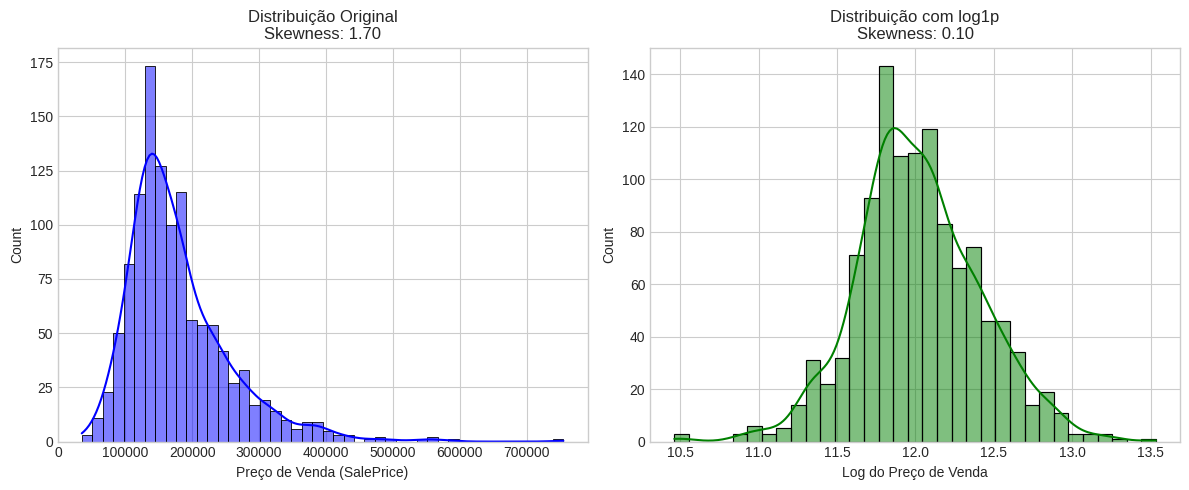

In [ ]:
# Configuração da figura
plt.figure(figsize=(12, 5))

# Distribuição Original (Assimetria à direita)
plt.subplot(1, 2, 1)
sns.histplot(y_train, kde=True, color='blue')
plt.title(f'Distribuição Original\nSkewness: {y_train.skew():.2f}')
plt.xlabel('Preço de Venda (SalePrice)')

# Distribuição após o LOG (Aproximação da Normal)
plt.subplot(1, 2, 2)
y_log = np.log1p(y_train)
sns.histplot(y_log, kde=True, color='green')
plt.title(f'Distribuição com log1p\nSkewness: {y_log.skew():.2f}')
plt.xlabel('Log do Preço de Venda')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.compose import TransformedTargetRegressor
# PASSO 6: Pipeline Final com Polinômios
# 1. preprocessor: Limpa e codifica (incluindo o TargetEncoder)
# 2. PCA
# 3. poly: Cria interações (ex: Area * Qualidade)
# 4. regressor: Treina o modelo linear nos dados expandidos só pelas interações
regressor_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False,interaction_only=True)),# Grau 2 é o padrão que recomendo
    ('scaler_pos_poly', StandardScaler()),
    #
    ('feature_selection', SelectKBest(score_func=mutual_info_regression, k=20)),
    ('regressor', LinearRegression())
])

# transformar o Alvo (SalePrice)
# O TransformedTargetRegressor automatiza o log no treino e exp no predict
model_final = TransformedTargetRegressor(
    regressor=regressor_pipeline,
    func=np.log1p,         # Aplica log(1+x) nos preços de treino
    inverse_func=np.expm1  # Aplica exp(x)-1 nas predições para voltar a Dólares
)

# Treinamento
# O fit agora aprende a relação entre os dados e o LOG do preço
model_final.fit(X_train, y_train)

# Avaliação de Performance
score_train = model_final.score(X_train, y_train)
score_test = model_final.score(X_test, y_test)

print(f"R² no Treino (Com Polinômios): {score_train:.4f}")
print(f"R² no Teste (Com Polinômios):  {score_test:.4f}")
n_colunas_final = model_final.regressor_.named_steps['regressor'].n_features_in_

print(f"Total de colunas entrando no modelo: {n_colunas_final}")

R² no Treino (Com Polinômios): 0.8455
R² no Teste (Com Polinômios):  0.8672
Total de colunas entrando no modelo: 20


Vamos fazer agora algumas modificações de carater didatico para aprendermos a encrementar o pipeline com outras funções.


In [ ]:
from sklearn.experimental import enable_iterative_imputer  # Necessário para habilitar
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import Binarizer
from sklearn.ensemble import RandomForestRegressor


# Definimos o transformador de Binarização com Imputação Avançada
# Exemplo: Queremos saber se a casa é "Recente" (construída após 1990)
binarizer_pipeline = Pipeline(steps=[
    ('iterative_impute', IterativeImputer(estimator=RandomForestRegressor(n_estimators=10, random_state=25),max_iter=10, random_state=25)),
    ('binarize', Binarizer(threshold=1990)),
    ('scaler', StandardScaler())
])

#Integramos no ColumnTransformer
# PASSO 5:
preprocessor = ColumnTransformer(
    transformers=[
        ('skew', skewed_transformer, skewed_features),
        ('num', numeric_transformer, list(set(numeric_features) - set(skewed_features))),
        ('ord', ordinal_transformer, ordinal_feature),
        ('cat', categorical_transformer, categorical_features),
         # Aplicando a lógica de binarização no ano
        ('is_modern', binarizer_pipeline, ['YearBuilt'])
    ]
)

# pipeline
regressor_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False,interaction_only=True)),# Grau 2 é o padrão que recomendo
    ('scaler_pos_poly', StandardScaler()),
    #
    ('feature_selection', SelectKBest(score_func=mutual_info_regression, k=20)),
    ('regressor', LinearRegression())
])

#  transformar o Alvo (SalePrice)
# O TransformedTargetRegressor automatiza o log no treino e exp no predict
model_final = TransformedTargetRegressor(
    regressor=regressor_pipeline,
    func=np.log1p,         # Aplica log(1+x) nos preços de treino
    inverse_func=np.expm1  # Aplica exp(x)-1 nas predições para voltar a Reais/Dólares
)

# Treinamento
# O fit agora aprende a relação entre os dados e o LOG do preço
model_final.fit(X_train, y_train)

# Avaliação de Performance
score_train = model_final.score(X_train, y_train)
score_test = model_final.score(X_test, y_test)

print(f"R² no Treino (Com Polinômios): {score_train:.4f}")
print(f"R² no Teste (Com Polinômios):  {score_test:.4f}")
n_colunas_final = model_final.regressor_.named_steps['regressor'].n_features_in_

print(f"Total de colunas entrando no modelo: {n_colunas_final}")


R² no Treino (Com Polinômios): 0.8454
R² no Teste (Com Polinômios):  0.8670
Total de colunas entrando no modelo: 20


Podemos crair as nossas proprias funções para o Pipeline

In [ ]:
from sklearn.preprocessing import FunctionTransformer
import numpy as np

# Definimos a lógica da função
# X é o array de dados que o pipeline enviará
def dividir_pela_media(X):
    # Calculamos a média de cada coluna (axis=0)
    media = np.mean(X, axis=0)
    return X / media

# Criamos o transformador customizado
media_transformer = FunctionTransformer(dividir_pela_media)

custom_eng_pipe = Pipeline(steps=[
    ('iterative_impute', IterativeImputer(max_iter=10)),
    ('div_media', FunctionTransformer(dividir_pela_media)),
    ('scaler', StandardScaler())
])

#  Inserindo no ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('eng_personalizada', custom_eng_pipe, ['GrLivArea']),
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

In [ ]:
# Garantir que as varaiveis vão estar na lista de variáveis independentes (X)
# Selecionar features e o alvo
features_selecionadas = [
    'LotArea', 'OverallQual', 'YearBuilt', 'GrLivArea', 'GarageCars', 'GarageArea',
    'MSZoning', 'Neighborhood', 'BldgType', 'GarageType', 'FireplaceQu', 'Street','YrSold','YearRemodAdd'
]
target = 'SalePrice'
df = df_original[features_selecionadas + [target]].copy() # ter um dataset completo

# >>>>>>>> PASSO 1:  Separar features (X) e alvo (y)
X = df.drop(target, axis=1)
y = df[target]


# Divisão de treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def calcular_recencia(X):
    # X virá como um DataFrame ou Array com 2 colunas
    # Coluna 0: Ano da Venda (Referência)
    # Coluna 1: Ano da Reforma (Evento)
    referencia = X[:, 0]
    evento = X[:, 1]

    # Calculamos a diferença (Recência)
    recencia = referencia - evento

    # Garantimos que não existam valores negativos (ex: reforma após a venda por erro de dado)
    recencia = np.maximum(recencia, 0)

    return recencia.reshape(-1, 1)

# Criamos o transformador
recencia_transformer = FunctionTransformer(calcular_recencia)

tempo_reforma_pipe = Pipeline(steps=[
    ('imputer', IterativeImputer(max_iter=10)), # Garante que não há nulos
    ('calc_recencia', recencia_transformer),
    ('scaler', StandardScaler())
])

#Integramos no ColumnTransformer
# PASSO 5:
preprocessor = ColumnTransformer(
    transformers=[
        ('skew', skewed_transformer, skewed_features),
        ('num', numeric_transformer, list(set(numeric_features) - set(skewed_features))),
        ('ord', ordinal_transformer, ordinal_feature),
        ('cat', categorical_transformer, categorical_features),
         # outros transformadores...
        ('idade_reforma', tempo_reforma_pipe, ['YrSold', 'YearRemodAdd'])
    ]
)

# pipeline
regressor_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False,interaction_only=True)),# Grau 2 é o padrão que recomendo
    ('scaler_pos_poly', StandardScaler()),
    #
    ('feature_selection', SelectKBest(score_func=mutual_info_regression, k=20)),
    ('regressor', LinearRegression())
])

#  Aplicamos o Wrapper para transformar o Alvo (SalePrice)
# O TransformedTargetRegressor automatiza o log no treino e exp no predict
model_final = TransformedTargetRegressor(
    regressor=regressor_pipeline,
    func=np.log1p,         # Aplica log(1+x) nos preços de treino
    inverse_func=np.expm1  # Aplica exp(x)-1 nas predições para voltar a Reais/Dólares
)

# Treinamento
# O fit agora aprende a relação entre os dados e o LOG do preço
model_final.fit(X_train, y_train)

# Avaliação de Performance
score_train = model_final.score(X_train, y_train)
score_test = model_final.score(X_test, y_test)

print(f"R² no Treino (Com Polinômios): {score_train:.4f}")
print(f"R² no Teste (Com Polinômios):  {score_test:.4f}")
n_colunas_final = model_final.regressor_.named_steps['regressor'].n_features_in_

print(f"Total de colunas entrando no modelo: {n_colunas_final}")


R² no Treino (Com Polinômios): 0.8502
R² no Teste (Com Polinômios):  0.8721
Total de colunas entrando no modelo: 20


Quando temos muitas colunas podemos fazer de modo automatico, mas so faça isso se for muito necessario(Bigdata)

In [ ]:
from sklearn.compose import make_column_selector

preprocessor = ColumnTransformer(transformers=[
    # Seleciona automaticamente tudo que for NÚMERO
    ('num', numeric_transformer, make_column_selector(dtype_include=['int64', 'float64'])),

    # Seleciona automaticamente tudo que for CATEGORIA (texto)
    ('cat', categorical_transformer, make_column_selector(dtype_include=['object'])),

    # Aceita expreçẽos regulares (Regex) Pega colunas que contenham a palavra 'Area' ou 'SF' (Square Footage)
    # Ex: LotArea, GrLivArea, 1stFlrSF, 2ndFlrSF
    ('dimensoes', StandardScaler(), make_column_selector(pattern='.*(Area|SF).*')),
])